# 5D chaotic memristive model: the 12 security / performance tests for image, audio and video


| No. | Test | Desired outcome |
|---|---|---|
| 1 | Shannon entropy | Near 8 bits (16 for 16-bit audio) |
| 2 | Correlation coefficient | Near 0 |
| 3 | NPCR | About 99.6 % |
| 4 | UACI | About 33.5 % |
| 5 | X/Y/Z time series | Bounded and non-repeating |
| 6 | Phase portraits | Attractor shape (this model: cap-like, paper Fig. 1) |
| 7 | Largest Lyapunov exponent | Positive |
| 8 | Initial-condition sensitivity | Nearly all output changes |
| 9 | Histogram chi-square | p-value above 0.05 |
| 10 | Key sensitivity | Large, unpredictable change |
| 11 | Effective key space | Large and well defined |
| 12 | Performance and throughput | High (software only) |

The algorithm is exactly the paper's: XOR with the chaotic signals x1, x2, x3 and with a key image / key audio / key video (no extra diffusion).  
Because of that, tests 3 and 4 (which need diffusion) are expected to FAIL.
Each cell ends with a summary table and saves it as a CSV file (`image_12_tests.csv`, `audio_12_tests.csv`, `video_12_tests.csv`).

## Cell 1: IMAGE

Upload the PLAIN image:
Upload the KEY image:
Plain image test_data.jpg: 250x334, key image key_image_from_video.png


Decrypted == original (every pixel identical): True


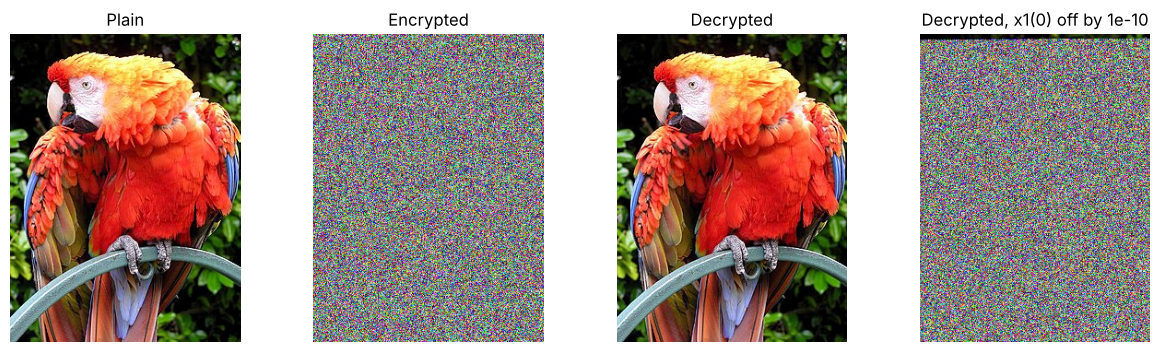

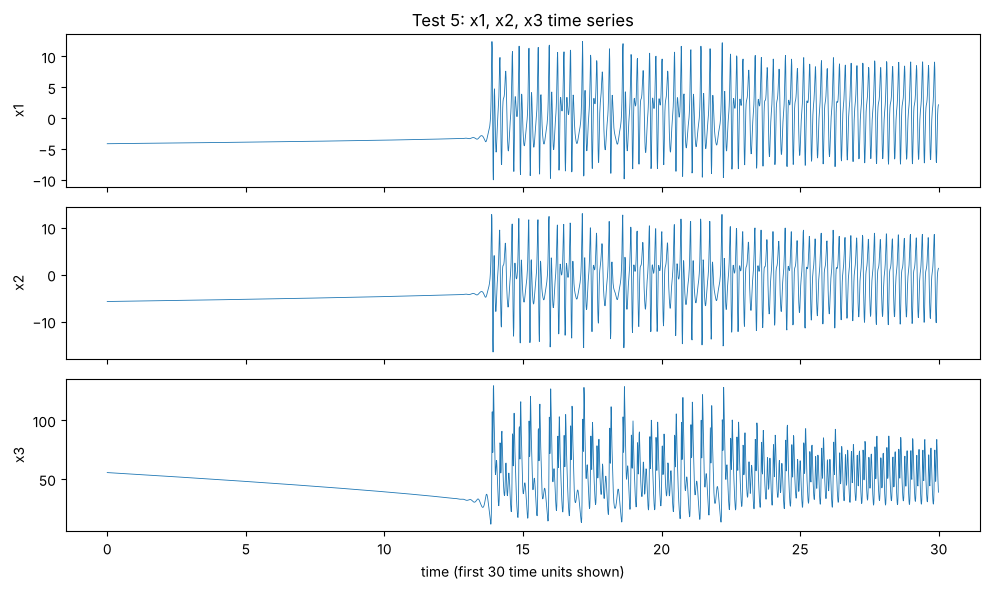

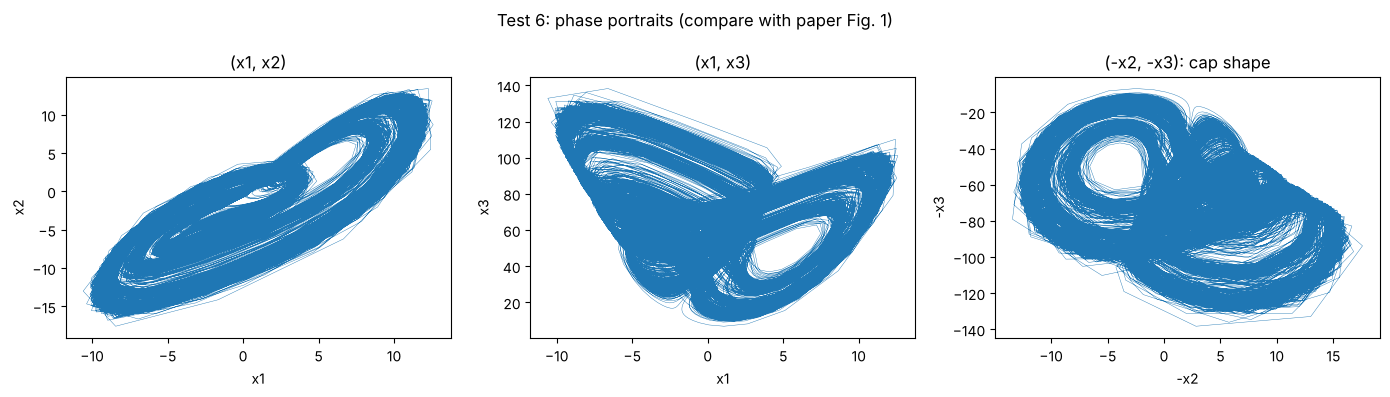

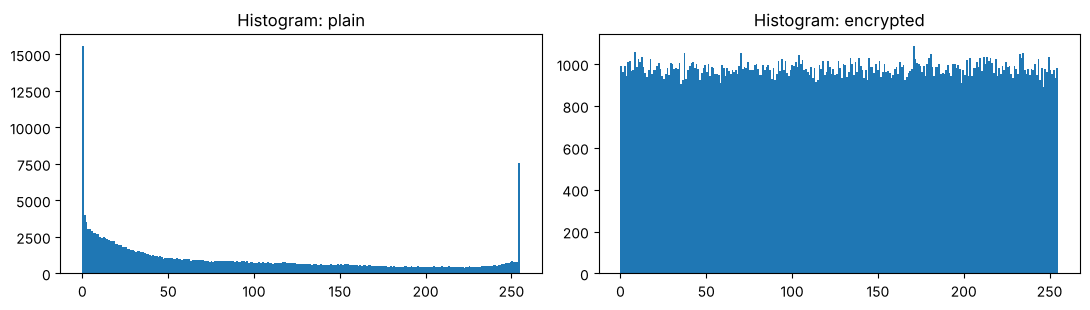


IMAGE ENCRYPTION: 12 TESTS
[ 1] Shannon entropy  ->  PASS
      measured: encrypted R/G/B = 7.9981 / 7.9978 / 7.9979 (ideal random sample of this size = 7.9978); plain R/G/B = 7.6052 / 7.6077 / 7.0631
      target  : Near 8 bits
[ 2] Correlation coefficient  ->  PASS
      measured: encrypted: max |r| = 0.0077 (H/V/D means -0.0047 / -0.0008 / 0.0013); plain: H/V/D means 0.923 / 0.945 / 0.897
      target  : Near 0
[ 3] NPCR  ->  FAIL
      measured: 0.00040 % (one plain byte +1, mean of 5 trials). Expected 1/250500 = 0.00040 % for a pure XOR cipher
      target  : About 99.6 %
[ 4] UACI  ->  FAIL
      measured: 0.00000 %
      target  : About 33.5 %
[ 5] X/Y/Z time series  ->  PASS
      measured: finite = True, max |x| = 138.2; strongest autocorrelation after the first zero crossing: x1 0.60, x2 0.59, x3 0.63 (a periodic signal would give ~1.0)
      target  : Bounded and non-repeating (autocorrelation clearly below 0.9)
[ 6] Phase portraits  ->  PASS
      measured: ranges: x1 [-10

,No,Test,Measured,Target,Status
0,1,Shannon entropy,encrypted R/G/B = 7.9981 / 7.9978 / 7.9979 (ideal random sample of this size = 7.9978); plain R/G/B = 7.6052 / 7.6077 / 7.0631,Near 8 bits,PASS
1,2,Correlation coefficient,encrypted: max |r| = 0.0077 (H/V/D means -0.0047 / -0.0008 / 0.0013); plain: H/V/D means 0.923 / 0.945 / 0.897,Near 0,PASS
2,3,NPCR,"0.00040 % (one plain byte +1, mean of 5 trials). Expected 1/250500 = 0.00040 % for a pure XOR cipher",About 99.6 %,FAIL
3,4,UACI,0.00000 %,About 33.5 %,FAIL
4,5,X/Y/Z time series,"finite = True, max |x| = 138.2; strongest autocorrelation after the first zero crossing: x1 0.60, x2 0.59, x3 0.63 (a periodic signal would give ~1.0)",Bounded and non-repeating (autocorrelation clearly below 0.9),PASS
5,6,Phase portraits,"ranges: x1 [-10.6, 12.6], x2 [-17.6, 13.4], x3 [6.8, 138.2] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1,PASS
6,7,Largest Lyapunov exponent,"LE1 = 0.6028 (own estimate, two-trajectory method, T = 200); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915,PASS
7,8,Initial-condition sensitivity,"each start value changed by 1e-10; keystream bytes changed over 83500 samples: x1(0) 98.1%, x2(0) 98.1%, x3(0) 98.1%, x4(0) 98.1%, x5(0) 98.1%; first different sample index: [1002, 458, 1131, 458, 1017]",Nearly all output changes (>= 95%),PASS
8,9,Histogram chi-square,encrypted p-value = 0.4636 (plain p-value = 0),p-value above 0.05,PASS
9,10,Key sensitivity,"x1(0) +1e-10: NPCR 98.10 %, UACI 36.63 %, PSNR 6.93 dB | parameter a +1e-10: NPCR 98.12 %, UACI 36.55 %, PSNR 6.96 dB | wrong key image: NPCR 100.00 %, UACI 62.82 %, PSNR 3.09 dB","Large, unpredictable change (decrypted image unrecognisable: PSNR < 15 dB, NPCR >= 90 %)",PASS



Note: tests 3 and 4 measure diffusion. The paper's algorithm is a plain XOR (no diffusion), so a one-value change in the plain image changes only one cipher value. A low NPCR/UACI here is a property of that design, not a coding error.


In [ ]:
import io, time, json, hashlib, subprocess, csv, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from scipy.io import wavfile
from google.colab import files

warnings.filterwarnings("ignore")
try:
    from numba import njit
    HAVE_NUMBA = True
except ImportError:
    HAVE_NUMBA = False
    def njit(f):
        return f
    print("WARNING: numba not found. The chaotic solver will be VERY slow (pip install numba).")

# =====================  chaotic model (Eq. 14), RK4 = alpha 1 case  =====================
@njit
def model(s, p):
    x1, x2, x3, x4, x5 = s[0], s[1], s[2], s[3], s[4]
    a, b, c, d, e, g, delta, gamma = p[0], p[1], p[2], p[3], p[4], p[5], p[6], p[7]
    out = np.empty(5)
    out[0] = a * (x2 - x1) + 0.25 * x3 + g * (delta + np.tanh(gamma * x5)) * x3
    out[1] = b * x1 - x1 * x3 + c * x2 - x4
    out[2] = d * x1 * x2 - e * x3
    out[3] = x1
    out[4] = x3
    return out

@njit
def rk4_step(s, p, h):
    k1 = model(s, p)
    k2 = model(s + 0.5 * h * k1, p)
    k3 = model(s + 0.5 * h * k2, p)
    k4 = model(s + h * k3, p)
    return s + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

@njit
def advance(s, p, h, n_steps):
    for _ in range(n_steps):
        s = rk4_step(s, p, h)
    return s

@njit
def generate_chunk(s, p, h, n_samples, skip):
    out = np.empty((n_samples, 3))
    for i in range(n_samples):
        for _ in range(skip):
            s = rk4_step(s, p, h)
        out[i, 0] = s[0]
        out[i, 1] = s[1]
        out[i, 2] = s[2]
    return out, s

@njit
def benettin(x0, p, h, n_transient, n_renorm, steps_per, d0):
    # largest Lyapunov exponent: two nearby trajectories, renormalised every steps_per steps
    s = advance(x0.copy(), p, h, n_transient)
    v = np.zeros(5)
    v[0] = 1.0
    s2 = s + d0 * v
    acc = 0.0
    for _ in range(n_renorm):
        for _ in range(steps_per):
            s = rk4_step(s, p, h)
            s2 = rk4_step(s2, p, h)
        dd = s2 - s
        nrm = np.sqrt(np.sum(dd * dd))
        acc += np.log(nrm / d0)
        s2 = s + dd * (d0 / nrm)
    return acc / (n_renorm * steps_per * h)

# =====================  secret key and settings  =====================
KEY = dict(
    a=78, b=-16, c=58, d=35, e=15, g=1, delta=1, gamma=0.5,   # paper values
    x0=[0.0, 0.0, 8.0, 6.0, 0.0],                             # initial conditions
)
H_STEP    = 0.001
TRANSIENT = 10000
SKIP      = 10
PARAM_NAMES = ['a', 'b', 'c', 'd', 'e', 'g', 'delta', 'gamma']
IC_NAMES    = ['x1(0)', 'x2(0)', 'x3(0)', 'x4(0)', 'x5(0)']

LE_TIME = 200      # time units used for the Lyapunov exponent (test 7)
IC_EPS  = 1e-10    # size of the tiny start-value change (tests 8 and 10)
KS_L    = 30000    # keystream samples used by the key-space scan (test 11)

def key_to_arrays(key):
    p  = np.array([key[n] for n in PARAM_NAMES], dtype=np.float64)
    x0 = np.array(key['x0'], dtype=np.float64)
    return x0, p

def perturb_key(key, name, eps):
    k = dict(key)
    k['x0'] = list(key['x0'])
    if name in IC_NAMES:
        k['x0'][IC_NAMES.index(name)] += eps
    else:
        k[name] = key[name] + eps
    return k

class ChaoticStream:
    """Chaotic orbit read in consecutive pieces (one piece per frame / signal)."""
    def __init__(self, key):
        x0, self.p = key_to_arrays(key)
        self.s = advance(x0.copy(), self.p, H_STEP, TRANSIENT)    # discard the transient once

    def take(self, n):
        orbit, self.s = generate_chunk(self.s, self.p, H_STEP, n, SKIP)
        if not np.all(np.isfinite(orbit)):
            raise ValueError("The chaotic system blew up. Check your key values.")
        return orbit                                              # (n, 3) = x1, x2, x3

    def byte_keystream(self, n):
        orbit = self.take(n)
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 256).astype(np.uint8)    # (n, 3)

    def frame_keystream(self, H, W):
        return self.byte_keystream(H * W).reshape(H, W, 3)

    def audio_keystream(self, n, channels):
        orbit = self.take(n)[:, :channels]
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 65536).astype(np.uint16)

_ = ChaoticStream(KEY).take(8)       # warm-up: compiles the numba functions so timings are fair

# =====================  helpers for the 12 tests  =====================
RESULTS = {}
def add(no, name, measured, target, status):
    RESULTS[no] = (name, measured, target, status)

def show_results(title, csv_name):
    rows = [(no,) + RESULTS[no] for no in sorted(RESULTS)]
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)
    for no, name, measured, target, status in rows:
        print(f"[{no:>2}] {name}  ->  {status}")
        print(f"      measured: {measured}")
        print(f"      target  : {target}")
    n_pass = sum(r[4] == 'PASS' for r in rows); n_fail = sum(r[4] == 'FAIL' for r in rows); n_info = sum(r[4] == 'INFO' for r in rows)
    print("-" * 100)
    print(f"PASS: {n_pass}   FAIL: {n_fail}   INFO: {n_info}   (12 tests)")
    with open(csv_name, 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['No', 'Test', 'Measured', 'Target', 'Status']); w.writerows([(r[0], r[1], r[2], r[3], r[4]) for r in rows])
    try:
        files.download(csv_name)
    except Exception:
        pass
    try:
        import pandas as pd
        from IPython.display import display
        pd.set_option('display.max_colwidth', None)
        display(pd.DataFrame(rows, columns=['No', 'Test', 'Measured', 'Target', 'Status']))
    except Exception:
        pass

def entropy_of(values, nbins):
    h = np.bincount(np.asarray(values).ravel(), minlength=nbins) / np.asarray(values).size
    h = h[h > 0]
    return float(-np.sum(h * np.log2(h)))

def entropy_reference(n, nbins, seed=1):
    # entropy of n ideal random values in nbins bins (the best a sample of this size can reach)
    return entropy_of(np.random.default_rng(seed).integers(0, nbins, n), nbins)

def chi2_p(counts):
    return float(stats.chisquare(counts).pvalue)

def corr(x, y):
    return float(np.corrcoef(np.asarray(x, np.float64).ravel(), np.asarray(y, np.float64).ravel())[0, 1])

def corr3(a2d):
    a = a2d.astype(np.float64)
    return [corr(a[:, :-1], a[:, 1:]), corr(a[:-1, :], a[1:, :]), corr(a[:-1, :-1], a[1:, 1:])]   # horizontal, vertical, diagonal

def npcr_uaci(a, b, maxval):
    a = a.astype(np.float64); b = b.astype(np.float64)
    return float((a != b).mean() * 100), float((np.abs(a - b) / maxval).mean() * 100)

def mse(a, b):
    return float(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2))

def psnr(a, b, maxval=255):
    m = mse(a, b)
    return float('inf') if m == 0 else float(10 * np.log10(maxval ** 2 / m))

def snr_db(ref, test):
    noise = np.sum((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float('inf') if noise == 0 else float(10 * np.log10(np.sum(ref.astype(np.float64) ** 2) / noise))

def bump_one(arr, rng, modulus, offset=0):
    """Copy of arr with ONE randomly chosen value increased by one unit (wraps around)."""
    a = arr.copy()
    flat = a.reshape(-1)
    i = int(rng.integers(0, flat.size))
    flat[i] = ((int(flat[i]) + offset + 1) % modulus) - offset
    return a

def model_level_tests(key, ks_len):
    """Tests 5, 6, 7, 8 and 11 (they depend only on the chaotic key, not on the data)."""
    x0, p = key_to_arrays(key)

    # ---- tests 5 + 6: time series and phase portraits (orbit of 20000 samples = 200 time units)
    n = 20000
    orbit = ChaoticStream(key).take(n)
    t = np.arange(n) * H_STEP * SKIP
    finite = bool(np.isfinite(orbit).all()); bound = float(np.abs(orbit).max())
    acs = []
    for k in range(3):
        x = orbit[:, k] - orbit[:, k].mean()
        f = np.fft.rfft(x, 2 * n); ac = np.fft.irfft(f * np.conj(f))[:n]; ac /= ac[0]
        z = int(np.argmax(ac < 0)); acs.append(float(ac[z:n // 2].max()))
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for k, nm in enumerate(['x1', 'x2', 'x3']):
        ax[k].plot(t[:3000], orbit[:3000, k], lw=0.6); ax[k].set_ylabel(nm)
    ax[2].set_xlabel('time (first 30 time units shown)'); ax[0].set_title('Test 5: x1, x2, x3 time series')
    plt.tight_layout(); plt.show()
    add(5, 'X/Y/Z time series',
        f"finite = {finite}, max |x| = {bound:.1f}; strongest autocorrelation after the first zero crossing: "
        f"x1 {acs[0]:.2f}, x2 {acs[1]:.2f}, x3 {acs[2]:.2f} (a periodic signal would give ~1.0)",
        'Bounded and non-repeating (autocorrelation clearly below 0.9)',
        'PASS' if (finite and bound < 1e4 and max(acs) < 0.9) else 'FAIL')

    rng_ = [(float(orbit[:, k].min()), float(orbit[:, k].max())) for k in range(3)]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].plot(orbit[:, 0], orbit[:, 1], lw=0.3); ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2'); ax[0].set_title('(x1, x2)')
    ax[1].plot(orbit[:, 0], orbit[:, 2], lw=0.3); ax[1].set_xlabel('x1'); ax[1].set_ylabel('x3'); ax[1].set_title('(x1, x3)')
    ax[2].plot(-orbit[:, 1], -orbit[:, 2], lw=0.3); ax[2].set_xlabel('-x2'); ax[2].set_ylabel('-x3'); ax[2].set_title('(-x2, -x3): cap shape')
    plt.suptitle('Test 6: phase portraits (compare with paper Fig. 1)'); plt.tight_layout(); plt.show()
    in_box = (-20 <= rng_[0][0] and rng_[0][1] <= 20 and -25 <= rng_[1][0] and rng_[1][1] <= 25 and -5 <= rng_[2][0] and rng_[2][1] <= 160)
    add(6, 'Phase portraits',
        f"ranges: x1 [{rng_[0][0]:.1f}, {rng_[0][1]:.1f}], x2 [{rng_[1][0]:.1f}, {rng_[1][1]:.1f}], x3 [{rng_[2][0]:.1f}, {rng_[2][1]:.1f}] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",
        'Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1',
        'PASS' if (finite and in_box) else 'FAIL')

    # ---- test 7: largest Lyapunov exponent
    n_renorm = int(LE_TIME / (H_STEP * 100))
    le = float(benettin(x0, p, H_STEP, TRANSIENT, n_renorm, 100, 1e-9))
    add(7, 'Largest Lyapunov exponent',
        f"LE1 = {le:.4f} (own estimate, two-trajectory method, T = {LE_TIME}); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",
        'Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915',
        'PASS' if le > 0.01 else 'FAIL')

    # ---- test 8: initial-condition sensitivity (tiny change in each start value)
    ref = ChaoticStream(key).byte_keystream(ks_len)
    fr, first = [], []
    for i, nm in enumerate(IC_NAMES):
        b = ChaoticStream(perturb_key(key, nm, IC_EPS)).byte_keystream(ks_len)
        ch = (b != ref)
        fr.append(float(ch.mean() * 100)); first.append(int(np.argmax(ch.any(axis=1))) if ch.any() else -1)
    add(8, 'Initial-condition sensitivity',
        f"each start value changed by {IC_EPS:g}; keystream bytes changed over {ks_len} samples: "
        + ', '.join(f"{nm} {v:.1f}%" for nm, v in zip(IC_NAMES, fr)) + f"; first different sample index: {first}",
        'Nearly all output changes (>= 95%)',
        'PASS' if min(fr) >= 95 else 'FAIL')

    # ---- test 11: effective key space (13 key values: 8 parameters + 5 initial conditions)
    refL = ChaoticStream(key).byte_keystream(KS_L)
    grid = [10.0 ** (-k) for k in range(16, 3, -1)]            # 1e-16 ... 1e-4
    def diverged(k2):
        return float((ChaoticStream(k2).byte_keystream(KS_L) != refL).mean()) >= 0.5
    parts, bits = [], 0.0
    for nm in IC_NAMES + PARAM_NAMES:
        val = key['x0'][IC_NAMES.index(nm)] if nm in IC_NAMES else key[nm]
        delta_i = None
        for j, eps in enumerate(grid):
            if diverged(perturb_key(key, nm, eps)) and (j + 1 >= len(grid) or diverged(perturb_key(key, nm, grid[j + 1]))):
                delta_i = eps; break
        if delta_i is None:
            parts.append(f"{nm}: no effect"); continue
        b_i = float(np.log2(max(abs(val), 1.0) / delta_i)); bits += b_i
        parts.append(f"{nm}: step {delta_i:.0e} ({b_i:.1f} bits)")
    add(11, 'Effective key space',
        f"about 2^{bits:.0f} distinguishable keys (13 key values; resolution where the keystream changes completely): " + '; '.join(parts) +
        ". Upper bound: assumes every key value can vary independently, and not every value stays chaotic",
        'Large and well defined (common requirement: at least 2^100)',
        'PASS' if bits >= 100 else 'FAIL')

# =====================  IMAGE: settings  =====================
USE_KEY_IMAGE = True       # second image used as an extra key (paper Fig. 6)
RESIZE_TO     = None       # e.g. 256 to shrink the plain image to 256 x 256 (None = keep size)

def upload_image(size=None, resize_to=None):
    up = files.upload()
    name = list(up.keys())[0]
    if len(up[name]) < 1000:
        raise ValueError(f"{name} is only {len(up[name])} bytes: empty or a placeholder. Upload the real image.")
    im = Image.open(io.BytesIO(up[name])).convert('RGB')
    if size is not None:
        im = im.resize(size)
    elif resize_to is not None:
        im = im.resize((resize_to, resize_to))
    return np.array(im, dtype=np.uint8), name

def encrypt_image(img, key, key_img=None):
    c = img ^ ChaoticStream(key).frame_keystream(img.shape[0], img.shape[1])     # R,G,B (x) x1,x2,x3
    if key_img is not None:
        c = c ^ key_img                                                          # (x) key image
    return c

decrypt_image = encrypt_image        # XOR is its own inverse

print("Upload the PLAIN image:")
plain, plain_name = upload_image(resize_to=RESIZE_TO)
H, W, _ = plain.shape
key_img = None
if USE_KEY_IMAGE:
    print("Upload the KEY image:")
    key_img, key_name = upload_image(size=(W, H))
print(f"Plain image {plain_name}: {W}x{H}" + (f", key image {key_name}" if key_img is not None else ", no key image"))

# =====================  encrypt and decrypt (timed)  =====================
t0 = time.perf_counter(); cipher = encrypt_image(plain, KEY, key_img); t_enc = time.perf_counter() - t0
t0 = time.perf_counter(); decrypted = decrypt_image(cipher, KEY, key_img); t_dec = time.perf_counter() - t0
print("Decrypted == original (every pixel identical):", np.array_equal(decrypted, plain))

bad_ic = decrypt_image(cipher, perturb_key(KEY, 'x1(0)', IC_EPS), key_img)
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, im, ttl in zip(ax, [plain, cipher, decrypted, bad_ic], ['Plain', 'Encrypted', 'Decrypted', f'Decrypted, x1(0) off by {IC_EPS:g}']):
    a.imshow(im); a.set_title(ttl); a.axis('off')
plt.show()

# =====================  the 12 tests  =====================
rng = np.random.default_rng(7)

# 1) Shannon entropy
ref8 = entropy_reference(H * W, 256)
ent_p = [entropy_of(plain[..., k], 256) for k in range(3)]
ent_c = [entropy_of(cipher[..., k], 256) for k in range(3)]
add(1, 'Shannon entropy',
    f"encrypted R/G/B = {ent_c[0]:.4f} / {ent_c[1]:.4f} / {ent_c[2]:.4f} (ideal random sample of this size = {ref8:.4f}); plain R/G/B = {ent_p[0]:.4f} / {ent_p[1]:.4f} / {ent_p[2]:.4f}",
    'Near 8 bits',
    'PASS' if min(ent_c) >= ref8 - 0.02 else 'FAIL')

# 2) Correlation coefficient (horizontal, vertical, diagonal neighbours)
cp = np.array([corr3(plain[..., k]) for k in range(3)])
cc = np.array([corr3(cipher[..., k]) for k in range(3)])
add(2, 'Correlation coefficient',
    f"encrypted: max |r| = {np.abs(cc).max():.4f} (H/V/D means {cc[:, 0].mean():.4f} / {cc[:, 1].mean():.4f} / {cc[:, 2].mean():.4f}); plain: H/V/D means {cp[:, 0].mean():.3f} / {cp[:, 1].mean():.3f} / {cp[:, 2].mean():.3f}",
    'Near 0',
    'PASS' if np.abs(cc).max() < 0.05 else 'FAIL')

# 3) + 4) NPCR and UACI after changing ONE plain value by one unit (5 random trials)
npcrs, uacis = [], []
for _ in range(5):
    c2 = encrypt_image(bump_one(plain, rng, 256), KEY, key_img)
    n_, u_ = npcr_uaci(cipher, c2, 255); npcrs.append(n_); uacis.append(u_)
npcr_m, uaci_m = float(np.mean(npcrs)), float(np.mean(uacis))
add(3, 'NPCR', f"{npcr_m:.5f} % (one plain byte +1, mean of 5 trials). Expected 1/{plain.size} = {100 / plain.size:.5f} % for a pure XOR cipher",
    'About 99.6 %', 'PASS' if npcr_m >= 99.0 else 'FAIL')
add(4, 'UACI', f"{uaci_m:.5f} %", 'About 33.5 %', 'PASS' if 32.0 <= uaci_m <= 35.0 else 'FAIL')

# 5), 6), 7), 8), 11) chaotic-key tests
model_level_tests(KEY, H * W)

# 9) Histogram chi-square (all encrypted bytes pooled into one test)
counts_c = np.bincount(cipher.ravel(), minlength=256); counts_p = np.bincount(plain.ravel(), minlength=256)
p_c, p_p = chi2_p(counts_c), chi2_p(counts_p)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(plain.ravel(), bins=256, range=(0, 255)); ax[0].set_title('Histogram: plain')
ax[1].hist(cipher.ravel(), bins=256, range=(0, 255)); ax[1].set_title('Histogram: encrypted')
plt.tight_layout(); plt.show()
add(9, 'Histogram chi-square', f"encrypted p-value = {p_c:.4f} (plain p-value = {p_p:.2g})", 'p-value above 0.05', 'PASS' if p_c > 0.05 else 'FAIL')

# 10) Key sensitivity: decrypt with a slightly wrong key
variants = [(f'x1(0) +{IC_EPS:g}', perturb_key(KEY, 'x1(0)', IC_EPS), key_img),
            (f'parameter a +{IC_EPS:g}', perturb_key(KEY, 'a', IC_EPS), key_img)]
if key_img is not None:
    variants.append(('wrong key image', KEY, 255 - key_img))
lines, ok10 = [], True
for nm, k2, ki2 in variants:
    d2 = decrypt_image(cipher, k2, ki2)
    n_, u_ = npcr_uaci(d2, plain, 255); ps = psnr(d2, plain)
    lines.append(f"{nm}: NPCR {n_:.2f} %, UACI {u_:.2f} %, PSNR {ps:.2f} dB")
    ok10 &= (n_ >= 90 and ps < 15)
add(10, 'Key sensitivity', ' | '.join(lines), 'Large, unpredictable change (decrypted image unrecognisable: PSNR < 15 dB, NPCR >= 90 %)', 'PASS' if ok10 else 'FAIL')

# 12) Performance and throughput
mb = plain.size / 1e6
add(12, 'Performance and throughput',
    f"{W}x{H} image ({mb:.2f} MB): encrypt {t_enc:.3f} s ({mb / t_enc:.2f} MB/s), decrypt {t_dec:.3f} s ({mb / t_dec:.2f} MB/s); numba = {HAVE_NUMBA}",
    'High (software only here)', 'INFO')

show_results("IMAGE ENCRYPTION: 12 TESTS", "image_12_tests.csv")
print("\nNote: tests 3 and 4 measure diffusion. The paper's algorithm is a plain XOR (no diffusion), so a one-value change in the plain image changes only one cipher value. A low NPCR/UACI here is a property of that design, not a coding error.")

## Cell 2: AUDIO

Upload the PLAIN audio (16-bit PCM wav):
Upload the KEY audio (16-bit PCM wav):
Plain audio test_sample-6s.wav: 44100 Hz, 2 channel(s), 6.39 s, key audio key_audio_from_video.wav


Decrypted == original (every sample identical): True


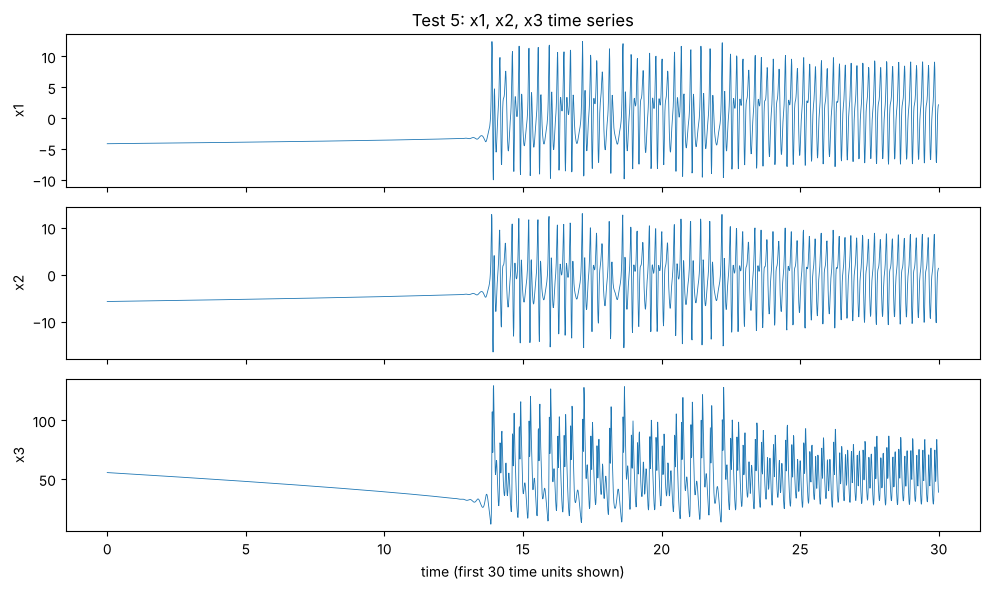

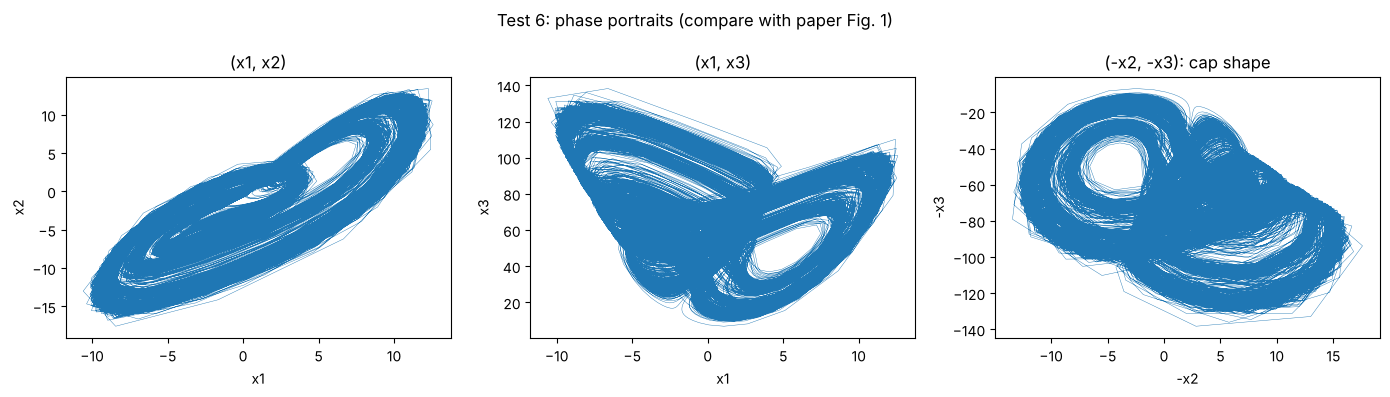

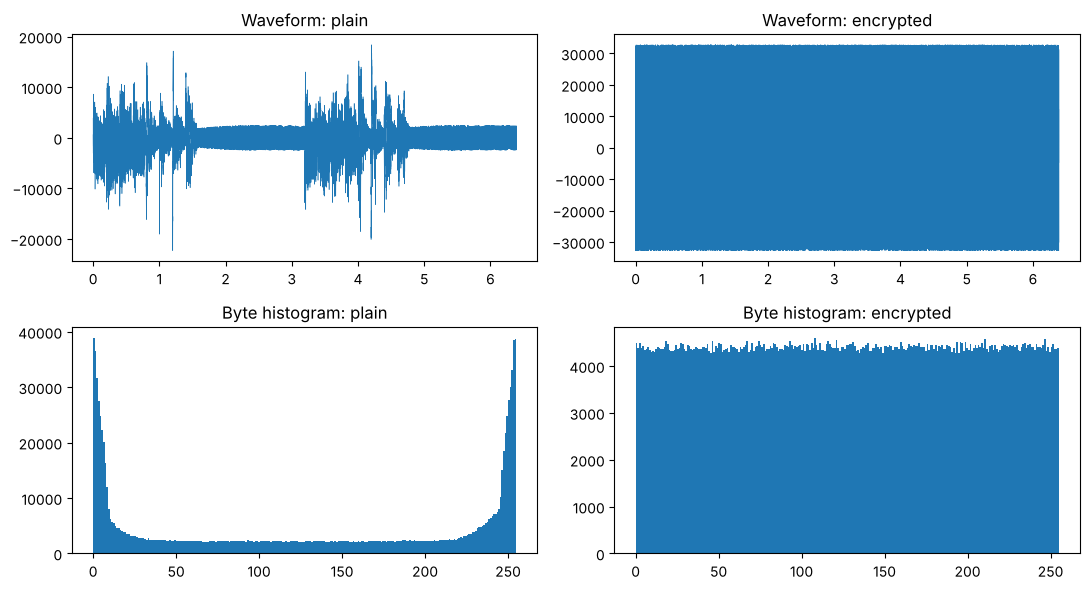


AUDIO ENCRYPTION: 12 TESTS
[ 1] Shannon entropy  ->  PASS
      measured: encrypted 16-bit = 15.9138 bits (ideal random sample of this size = 15.9136, max 16); encrypted byte entropy = 7.9999 (max 8); plain: 16-bit 13.123, byte 7.205
      target  : Near 16 bits for 16-bit audio (near 8 per byte)
[ 2] Correlation coefficient  ->  PASS
      measured: encrypted adjacent-sample r per channel = [0.0046, -0.0003]; plain = [0.9902, 0.9902]
      target  : Near 0
[ 3] NPCR  ->  FAIL
      measured: 0.00018 % (one plain sample +1, mean of 5 trials). Expected 1/563712 = 0.00018 % for a pure XOR cipher
      target  : About 99.6 %
[ 4] UACI  ->  FAIL
      measured: 0.000000 %
      target  : About 33.5 %
[ 5] X/Y/Z time series  ->  PASS
      measured: finite = True, max |x| = 138.2; strongest autocorrelation after the first zero crossing: x1 0.60, x2 0.59, x3 0.63 (a periodic signal would give ~1.0)
      target  : Bounded and non-repeating (autocorrelation clearly below 0.9)
[ 6] Phase port

,No,Test,Measured,Target,Status
0,1,Shannon entropy,"encrypted 16-bit = 15.9138 bits (ideal random sample of this size = 15.9136, max 16); encrypted byte entropy = 7.9999 (max 8); plain: 16-bit 13.123, byte 7.205",Near 16 bits for 16-bit audio (near 8 per byte),PASS
1,2,Correlation coefficient,"encrypted adjacent-sample r per channel = [0.0046, -0.0003]; plain = [0.9902, 0.9902]",Near 0,PASS
2,3,NPCR,"0.00018 % (one plain sample +1, mean of 5 trials). Expected 1/563712 = 0.00018 % for a pure XOR cipher",About 99.6 %,FAIL
3,4,UACI,0.000000 %,About 33.5 %,FAIL
4,5,X/Y/Z time series,"finite = True, max |x| = 138.2; strongest autocorrelation after the first zero crossing: x1 0.60, x2 0.59, x3 0.63 (a periodic signal would give ~1.0)",Bounded and non-repeating (autocorrelation clearly below 0.9),PASS
5,6,Phase portraits,"ranges: x1 [-10.6, 12.6], x2 [-17.6, 13.4], x3 [6.8, 138.2] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1,PASS
6,7,Largest Lyapunov exponent,"LE1 = 0.6028 (own estimate, two-trajectory method, T = 200); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915,PASS
7,8,Initial-condition sensitivity,"each start value changed by 1e-10; keystream bytes changed over 281856 samples: x1(0) 99.2%, x2(0) 99.2%, x3(0) 99.1%, x4(0) 99.2%, x5(0) 99.2%; first different sample index: [1002, 458, 1131, 458, 1017]",Nearly all output changes (>= 95%),PASS
8,9,Histogram chi-square,encrypted byte-histogram p-value = 0.8243 (plain p-value = 0),p-value above 0.05,PASS
9,10,Key sensitivity,"x1(0) +1e-10: NPCR 99.54 %, UACI 25.03 %, SNR -16.75 dB | parameter a +1e-10: NPCR 99.55 %, UACI 25.04 %, SNR -16.75 dB | wrong key audio (reversed): NPCR 99.99 %, UACI 8.70 %, SNR -8.78 dB","Large, unpredictable change (decrypted audio is noise: SNR < 0 dB, NPCR >= 90 %)",PASS



Note: tests 3 and 4 measure diffusion. A plain XOR cipher has none, so a one-sample change in the plain audio changes only one cipher sample. A low NPCR/UACI here is a property of that design, not a coding error.


In [ ]:
import io, time, json, hashlib, subprocess, csv, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from scipy.io import wavfile
from google.colab import files

warnings.filterwarnings("ignore")
try:
    from numba import njit
    HAVE_NUMBA = True
except ImportError:
    HAVE_NUMBA = False
    def njit(f):
        return f
    print("WARNING: numba not found. The chaotic solver will be VERY slow (pip install numba).")

# =====================  chaotic model (Eq. 14), RK4 = alpha 1 case  =====================
@njit
def model(s, p):
    x1, x2, x3, x4, x5 = s[0], s[1], s[2], s[3], s[4]
    a, b, c, d, e, g, delta, gamma = p[0], p[1], p[2], p[3], p[4], p[5], p[6], p[7]
    out = np.empty(5)
    out[0] = a * (x2 - x1) + 0.25 * x3 + g * (delta + np.tanh(gamma * x5)) * x3
    out[1] = b * x1 - x1 * x3 + c * x2 - x4
    out[2] = d * x1 * x2 - e * x3
    out[3] = x1
    out[4] = x3
    return out

@njit
def rk4_step(s, p, h):
    k1 = model(s, p)
    k2 = model(s + 0.5 * h * k1, p)
    k3 = model(s + 0.5 * h * k2, p)
    k4 = model(s + h * k3, p)
    return s + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

@njit
def advance(s, p, h, n_steps):
    for _ in range(n_steps):
        s = rk4_step(s, p, h)
    return s

@njit
def generate_chunk(s, p, h, n_samples, skip):
    out = np.empty((n_samples, 3))
    for i in range(n_samples):
        for _ in range(skip):
            s = rk4_step(s, p, h)
        out[i, 0] = s[0]
        out[i, 1] = s[1]
        out[i, 2] = s[2]
    return out, s

@njit
def benettin(x0, p, h, n_transient, n_renorm, steps_per, d0):
    # largest Lyapunov exponent: two nearby trajectories, renormalised every steps_per steps
    s = advance(x0.copy(), p, h, n_transient)
    v = np.zeros(5)
    v[0] = 1.0
    s2 = s + d0 * v
    acc = 0.0
    for _ in range(n_renorm):
        for _ in range(steps_per):
            s = rk4_step(s, p, h)
            s2 = rk4_step(s2, p, h)
        dd = s2 - s
        nrm = np.sqrt(np.sum(dd * dd))
        acc += np.log(nrm / d0)
        s2 = s + dd * (d0 / nrm)
    return acc / (n_renorm * steps_per * h)

# =====================  secret key and settings  =====================
KEY = dict(
    a=78, b=-16, c=58, d=35, e=15, g=1, delta=1, gamma=0.5,   # paper values
    x0=[0.0, 0.0, 8.0, 6.0, 0.0],                             # initial conditions
)
H_STEP    = 0.001
TRANSIENT = 10000
SKIP      = 10
PARAM_NAMES = ['a', 'b', 'c', 'd', 'e', 'g', 'delta', 'gamma']
IC_NAMES    = ['x1(0)', 'x2(0)', 'x3(0)', 'x4(0)', 'x5(0)']

LE_TIME = 200      # time units used for the Lyapunov exponent (test 7)
IC_EPS  = 1e-10    # size of the tiny start-value change (tests 8 and 10)
KS_L    = 30000    # keystream samples used by the key-space scan (test 11)

def key_to_arrays(key):
    p  = np.array([key[n] for n in PARAM_NAMES], dtype=np.float64)
    x0 = np.array(key['x0'], dtype=np.float64)
    return x0, p

def perturb_key(key, name, eps):
    k = dict(key)
    k['x0'] = list(key['x0'])
    if name in IC_NAMES:
        k['x0'][IC_NAMES.index(name)] += eps
    else:
        k[name] = key[name] + eps
    return k

class ChaoticStream:
    """Chaotic orbit read in consecutive pieces (one piece per frame / signal)."""
    def __init__(self, key):
        x0, self.p = key_to_arrays(key)
        self.s = advance(x0.copy(), self.p, H_STEP, TRANSIENT)    # discard the transient once

    def take(self, n):
        orbit, self.s = generate_chunk(self.s, self.p, H_STEP, n, SKIP)
        if not np.all(np.isfinite(orbit)):
            raise ValueError("The chaotic system blew up. Check your key values.")
        return orbit                                              # (n, 3) = x1, x2, x3

    def byte_keystream(self, n):
        orbit = self.take(n)
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 256).astype(np.uint8)    # (n, 3)

    def frame_keystream(self, H, W):
        return self.byte_keystream(H * W).reshape(H, W, 3)

    def audio_keystream(self, n, channels):
        orbit = self.take(n)[:, :channels]
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 65536).astype(np.uint16)

_ = ChaoticStream(KEY).take(8)       # warm-up: compiles the numba functions so timings are fair

# =====================  helpers for the 12 tests  =====================
RESULTS = {}
def add(no, name, measured, target, status):
    RESULTS[no] = (name, measured, target, status)

def show_results(title, csv_name):
    rows = [(no,) + RESULTS[no] for no in sorted(RESULTS)]
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)
    for no, name, measured, target, status in rows:
        print(f"[{no:>2}] {name}  ->  {status}")
        print(f"      measured: {measured}")
        print(f"      target  : {target}")
    n_pass = sum(r[4] == 'PASS' for r in rows); n_fail = sum(r[4] == 'FAIL' for r in rows); n_info = sum(r[4] == 'INFO' for r in rows)
    print("-" * 100)
    print(f"PASS: {n_pass}   FAIL: {n_fail}   INFO: {n_info}   (12 tests)")
    with open(csv_name, 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['No', 'Test', 'Measured', 'Target', 'Status']); w.writerows([(r[0], r[1], r[2], r[3], r[4]) for r in rows])
    try:
        files.download(csv_name)
    except Exception:
        pass
    try:
        import pandas as pd
        from IPython.display import display
        pd.set_option('display.max_colwidth', None)
        display(pd.DataFrame(rows, columns=['No', 'Test', 'Measured', 'Target', 'Status']))
    except Exception:
        pass

def entropy_of(values, nbins):
    h = np.bincount(np.asarray(values).ravel(), minlength=nbins) / np.asarray(values).size
    h = h[h > 0]
    return float(-np.sum(h * np.log2(h)))

def entropy_reference(n, nbins, seed=1):
    # entropy of n ideal random values in nbins bins (the best a sample of this size can reach)
    return entropy_of(np.random.default_rng(seed).integers(0, nbins, n), nbins)

def chi2_p(counts):
    return float(stats.chisquare(counts).pvalue)

def corr(x, y):
    return float(np.corrcoef(np.asarray(x, np.float64).ravel(), np.asarray(y, np.float64).ravel())[0, 1])

def corr3(a2d):
    a = a2d.astype(np.float64)
    return [corr(a[:, :-1], a[:, 1:]), corr(a[:-1, :], a[1:, :]), corr(a[:-1, :-1], a[1:, 1:])]   # horizontal, vertical, diagonal

def npcr_uaci(a, b, maxval):
    a = a.astype(np.float64); b = b.astype(np.float64)
    return float((a != b).mean() * 100), float((np.abs(a - b) / maxval).mean() * 100)

def mse(a, b):
    return float(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2))

def psnr(a, b, maxval=255):
    m = mse(a, b)
    return float('inf') if m == 0 else float(10 * np.log10(maxval ** 2 / m))

def snr_db(ref, test):
    noise = np.sum((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float('inf') if noise == 0 else float(10 * np.log10(np.sum(ref.astype(np.float64) ** 2) / noise))

def bump_one(arr, rng, modulus, offset=0):
    """Copy of arr with ONE randomly chosen value increased by one unit (wraps around)."""
    a = arr.copy()
    flat = a.reshape(-1)
    i = int(rng.integers(0, flat.size))
    flat[i] = ((int(flat[i]) + offset + 1) % modulus) - offset
    return a

def model_level_tests(key, ks_len):
    """Tests 5, 6, 7, 8 and 11 (they depend only on the chaotic key, not on the data)."""
    x0, p = key_to_arrays(key)

    # ---- tests 5 + 6: time series and phase portraits (orbit of 20000 samples = 200 time units)
    n = 20000
    orbit = ChaoticStream(key).take(n)
    t = np.arange(n) * H_STEP * SKIP
    finite = bool(np.isfinite(orbit).all()); bound = float(np.abs(orbit).max())
    acs = []
    for k in range(3):
        x = orbit[:, k] - orbit[:, k].mean()
        f = np.fft.rfft(x, 2 * n); ac = np.fft.irfft(f * np.conj(f))[:n]; ac /= ac[0]
        z = int(np.argmax(ac < 0)); acs.append(float(ac[z:n // 2].max()))
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for k, nm in enumerate(['x1', 'x2', 'x3']):
        ax[k].plot(t[:3000], orbit[:3000, k], lw=0.6); ax[k].set_ylabel(nm)
    ax[2].set_xlabel('time (first 30 time units shown)'); ax[0].set_title('Test 5: x1, x2, x3 time series')
    plt.tight_layout(); plt.show()
    add(5, 'X/Y/Z time series',
        f"finite = {finite}, max |x| = {bound:.1f}; strongest autocorrelation after the first zero crossing: "
        f"x1 {acs[0]:.2f}, x2 {acs[1]:.2f}, x3 {acs[2]:.2f} (a periodic signal would give ~1.0)",
        'Bounded and non-repeating (autocorrelation clearly below 0.9)',
        'PASS' if (finite and bound < 1e4 and max(acs) < 0.9) else 'FAIL')

    rng_ = [(float(orbit[:, k].min()), float(orbit[:, k].max())) for k in range(3)]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].plot(orbit[:, 0], orbit[:, 1], lw=0.3); ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2'); ax[0].set_title('(x1, x2)')
    ax[1].plot(orbit[:, 0], orbit[:, 2], lw=0.3); ax[1].set_xlabel('x1'); ax[1].set_ylabel('x3'); ax[1].set_title('(x1, x3)')
    ax[2].plot(-orbit[:, 1], -orbit[:, 2], lw=0.3); ax[2].set_xlabel('-x2'); ax[2].set_ylabel('-x3'); ax[2].set_title('(-x2, -x3): cap shape')
    plt.suptitle('Test 6: phase portraits (compare with paper Fig. 1)'); plt.tight_layout(); plt.show()
    in_box = (-20 <= rng_[0][0] and rng_[0][1] <= 20 and -25 <= rng_[1][0] and rng_[1][1] <= 25 and -5 <= rng_[2][0] and rng_[2][1] <= 160)
    add(6, 'Phase portraits',
        f"ranges: x1 [{rng_[0][0]:.1f}, {rng_[0][1]:.1f}], x2 [{rng_[1][0]:.1f}, {rng_[1][1]:.1f}], x3 [{rng_[2][0]:.1f}, {rng_[2][1]:.1f}] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",
        'Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1',
        'PASS' if (finite and in_box) else 'FAIL')

    # ---- test 7: largest Lyapunov exponent
    n_renorm = int(LE_TIME / (H_STEP * 100))
    le = float(benettin(x0, p, H_STEP, TRANSIENT, n_renorm, 100, 1e-9))
    add(7, 'Largest Lyapunov exponent',
        f"LE1 = {le:.4f} (own estimate, two-trajectory method, T = {LE_TIME}); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",
        'Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915',
        'PASS' if le > 0.01 else 'FAIL')

    # ---- test 8: initial-condition sensitivity (tiny change in each start value)
    ref = ChaoticStream(key).byte_keystream(ks_len)
    fr, first = [], []
    for i, nm in enumerate(IC_NAMES):
        b = ChaoticStream(perturb_key(key, nm, IC_EPS)).byte_keystream(ks_len)
        ch = (b != ref)
        fr.append(float(ch.mean() * 100)); first.append(int(np.argmax(ch.any(axis=1))) if ch.any() else -1)
    add(8, 'Initial-condition sensitivity',
        f"each start value changed by {IC_EPS:g}; keystream bytes changed over {ks_len} samples: "
        + ', '.join(f"{nm} {v:.1f}%" for nm, v in zip(IC_NAMES, fr)) + f"; first different sample index: {first}",
        'Nearly all output changes (>= 95%)',
        'PASS' if min(fr) >= 95 else 'FAIL')

    # ---- test 11: effective key space (13 key values: 8 parameters + 5 initial conditions)
    refL = ChaoticStream(key).byte_keystream(KS_L)
    grid = [10.0 ** (-k) for k in range(16, 3, -1)]            # 1e-16 ... 1e-4
    def diverged(k2):
        return float((ChaoticStream(k2).byte_keystream(KS_L) != refL).mean()) >= 0.5
    parts, bits = [], 0.0
    for nm in IC_NAMES + PARAM_NAMES:
        val = key['x0'][IC_NAMES.index(nm)] if nm in IC_NAMES else key[nm]
        delta_i = None
        for j, eps in enumerate(grid):
            if diverged(perturb_key(key, nm, eps)) and (j + 1 >= len(grid) or diverged(perturb_key(key, nm, grid[j + 1]))):
                delta_i = eps; break
        if delta_i is None:
            parts.append(f"{nm}: no effect"); continue
        b_i = float(np.log2(max(abs(val), 1.0) / delta_i)); bits += b_i
        parts.append(f"{nm}: step {delta_i:.0e} ({b_i:.1f} bits)")
    add(11, 'Effective key space',
        f"about 2^{bits:.0f} distinguishable keys (13 key values; resolution where the keystream changes completely): " + '; '.join(parts) +
        ". Upper bound: assumes every key value can vary independently, and not every value stays chaotic",
        'Large and well defined (common requirement: at least 2^100)',
        'PASS' if bits >= 100 else 'FAIL')

# =====================  AUDIO: settings  =====================
USE_KEY_AUDIO = True       # second audio used as an extra key
MAX_SECONDS   = 10         # only the first N seconds are processed (None = whole file)

def to_pcm16(data, name):
    """16-bit PCM numpy array + sample rate. Non-16-bit files / other formats are converted with ffmpeg."""
    if len(data) < 1000:
        raise ValueError(f"{name} is only {len(data)} bytes: empty or a placeholder. Upload the real file.")
    try:
        sr, x = wavfile.read(io.BytesIO(data))
        if x.dtype == np.int16:
            return sr, np.ascontiguousarray(x)
    except Exception:
        pass
    with open(name, 'wb') as f:
        f.write(data)
    r = subprocess.run(['ffmpeg', '-y', '-v', 'error', '-i', name, '-vn', '-acodec', 'pcm_s16le', 'tmp_conv.wav'], capture_output=True)
    if r.returncode != 0:
        raise ValueError(f"Cannot read audio from {name}: " + r.stderr.decode(errors='ignore')[-300:])
    sr, x = wavfile.read('tmp_conv.wav')
    return sr, np.ascontiguousarray(x)

def as_2d(x):
    return x.reshape(-1, 1) if x.ndim == 1 else x

def prepare_key_audio(key_audio, n, ch):
    k = as_2d(key_audio)
    k = np.tile(k, (int(np.ceil(n / k.shape[0])), 1))[:n]
    k = k[:, :ch] if k.shape[1] >= ch else np.tile(k[:, :1], (1, ch))
    return np.ascontiguousarray(k).view(np.uint16)

def encrypt_audio(audio, key, key_audio=None):
    a2 = np.ascontiguousarray(as_2d(audio))
    n, ch = a2.shape
    c = a2.view(np.uint16) ^ ChaoticStream(key).audio_keystream(n, ch)          # 16-bit sample (x) chaotic value
    if key_audio is not None:
        c = c ^ prepare_key_audio(key_audio, n, ch)                              # (x) key audio
    return c.view(np.int16).reshape(audio.shape)

decrypt_audio = encrypt_audio        # XOR is its own inverse

print("Upload the PLAIN audio (16-bit PCM wav):")
up = files.upload(); plain_name = list(up.keys())[0]
sr, plain = to_pcm16(up[plain_name], plain_name)
if MAX_SECONDS:
    plain = np.ascontiguousarray(plain[: int(sr * MAX_SECONDS)])
key_audio = None
if USE_KEY_AUDIO:
    print("Upload the KEY audio (16-bit PCM wav):")
    up = files.upload(); key_name = list(up.keys())[0]
    _, key_audio = to_pcm16(up[key_name], key_name)
n_samples = plain.shape[0]; n_ch = as_2d(plain).shape[1]
print(f"Plain audio {plain_name}: {sr} Hz, {n_ch} channel(s), {n_samples / sr:.2f} s" + (f", key audio {key_name}" if key_audio is not None else ", no key audio"))

# =====================  encrypt and decrypt (timed)  =====================
t0 = time.perf_counter(); cipher = encrypt_audio(plain, KEY, key_audio); t_enc = time.perf_counter() - t0
t0 = time.perf_counter(); decrypted = decrypt_audio(cipher, KEY, key_audio); t_dec = time.perf_counter() - t0
print("Decrypted == original (every sample identical):", np.array_equal(decrypted, plain))

# =====================  the 12 tests  =====================
rng = np.random.default_rng(7)
P2, C2 = as_2d(plain), as_2d(cipher)

# 1) Shannon entropy (16-bit sample values, and the 8-bit bytes)
N16 = P2.size
ref16 = entropy_reference(N16, 65536)
e16_p = entropy_of(P2.view(np.uint16), 65536); e16_c = entropy_of(C2.view(np.uint16), 65536)
bytes_c = np.ascontiguousarray(C2).view(np.uint8); bytes_p = np.ascontiguousarray(P2).view(np.uint8)
ref8 = entropy_reference(bytes_c.size, 256)
e8_p = entropy_of(bytes_p, 256); e8_c = entropy_of(bytes_c, 256)
add(1, 'Shannon entropy',
    f"encrypted 16-bit = {e16_c:.4f} bits (ideal random sample of this size = {ref16:.4f}, max 16); encrypted byte entropy = {e8_c:.4f} (max 8); plain: 16-bit {e16_p:.3f}, byte {e8_p:.3f}",
    'Near 16 bits for 16-bit audio (near 8 per byte)',
    'PASS' if (e16_c >= ref16 - 0.02 and e8_c >= ref8 - 0.01) else 'FAIL')

# 2) Correlation of neighbouring samples (lag 1), per channel
cp = [corr(P2[:-1, k], P2[1:, k]) for k in range(n_ch)]
cc = [corr(C2[:-1, k], C2[1:, k]) for k in range(n_ch)]
add(2, 'Correlation coefficient',
    f"encrypted adjacent-sample r per channel = {[round(v, 4) for v in cc]}; plain = {[round(v, 4) for v in cp]}",
    'Near 0', 'PASS' if max(abs(v) for v in cc) < 0.05 else 'FAIL')

# 3) + 4) NPCR and UACI after changing ONE plain sample by one unit (5 random trials)
npcrs, uacis = [], []
for _ in range(5):
    c2 = encrypt_audio(bump_one(plain, rng, 65536, offset=32768), KEY, key_audio)
    n_, u_ = npcr_uaci(cipher, c2, 65535); npcrs.append(n_); uacis.append(u_)
npcr_m, uaci_m = float(np.mean(npcrs)), float(np.mean(uacis))
add(3, 'NPCR', f"{npcr_m:.5f} % (one plain sample +1, mean of 5 trials). Expected 1/{plain.size} = {100 / plain.size:.5f} % for a pure XOR cipher",
    'About 99.6 %', 'PASS' if npcr_m >= 99.0 else 'FAIL')
add(4, 'UACI', f"{uaci_m:.6f} %", 'About 33.5 %', 'PASS' if 32.0 <= uaci_m <= 35.0 else 'FAIL')

# 5), 6), 7), 8), 11) chaotic-key tests
model_level_tests(KEY, n_samples)

# 9) Histogram chi-square (all encrypted bytes pooled into one test)
p_c = chi2_p(np.bincount(bytes_c.ravel(), minlength=256)); p_p = chi2_p(np.bincount(bytes_p.ravel(), minlength=256))
fig, ax = plt.subplots(2, 2, figsize=(11, 6))
tt = np.arange(n_samples) / sr
ax[0, 0].plot(tt, P2[:, 0], lw=0.4); ax[0, 0].set_title('Waveform: plain')
ax[0, 1].plot(tt, C2[:, 0], lw=0.4); ax[0, 1].set_title('Waveform: encrypted')
ax[1, 0].hist(bytes_p.ravel(), bins=256, range=(0, 255)); ax[1, 0].set_title('Byte histogram: plain')
ax[1, 1].hist(bytes_c.ravel(), bins=256, range=(0, 255)); ax[1, 1].set_title('Byte histogram: encrypted')
plt.tight_layout(); plt.show()
add(9, 'Histogram chi-square', f"encrypted byte-histogram p-value = {p_c:.4f} (plain p-value = {p_p:.2g})", 'p-value above 0.05', 'PASS' if p_c > 0.05 else 'FAIL')

# 10) Key sensitivity: decrypt with a slightly wrong key
variants = [(f'x1(0) +{IC_EPS:g}', perturb_key(KEY, 'x1(0)', IC_EPS), key_audio),
            (f'parameter a +{IC_EPS:g}', perturb_key(KEY, 'a', IC_EPS), key_audio)]
if key_audio is not None:
    variants.append(('wrong key audio (reversed)', KEY, np.ascontiguousarray(key_audio[::-1])))
lines, ok10 = [], True
for nm, k2, ka2 in variants:
    d2 = decrypt_audio(cipher, k2, ka2)
    n_, u_ = npcr_uaci(d2, plain, 65535); sn = snr_db(plain, d2)
    lines.append(f"{nm}: NPCR {n_:.2f} %, UACI {u_:.2f} %, SNR {sn:.2f} dB")
    ok10 &= (n_ >= 90 and sn < 0)
add(10, 'Key sensitivity', ' | '.join(lines), 'Large, unpredictable change (decrypted audio is noise: SNR < 0 dB, NPCR >= 90 %)', 'PASS' if ok10 else 'FAIL')

# 12) Performance and throughput
mb = plain.nbytes / 1e6; dur = n_samples / sr
add(12, 'Performance and throughput',
    f"{dur:.2f} s of audio ({mb:.2f} MB): encrypt {t_enc:.3f} s ({mb / t_enc:.2f} MB/s, {dur / t_enc:.1f}x real time), decrypt {t_dec:.3f} s ({mb / t_dec:.2f} MB/s); numba = {HAVE_NUMBA}",
    'High (software only here)', 'INFO')

show_results("AUDIO ENCRYPTION: 12 TESTS", "audio_12_tests.csv")
print("\nNote: tests 3 and 4 measure diffusion. A plain XOR cipher has none, so a one-sample change in the plain audio changes only one cipher sample. A low NPCR/UACI here is a property of that design, not a coding error.")

## Cell 3: VIDEO = frames + audio

Upload the PLAIN video:


Upload the KEY video (different from the plain video):
Plain video test_data.mp4: 1920x1080 -> working size 320x180, 150 frames at 30/1 fps; audio 48000 Hz (240000, 2); key: image yes, audio yes


All frames identical to the original: True (150 frames)
Audio identical to the original     : True


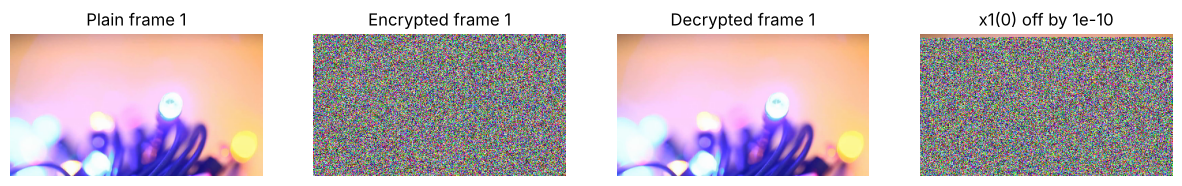

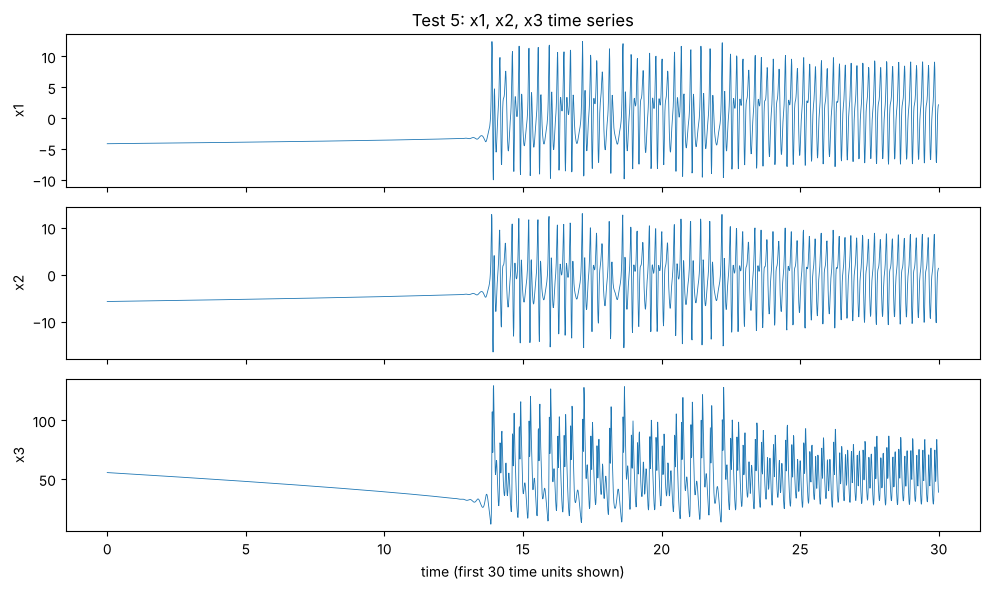

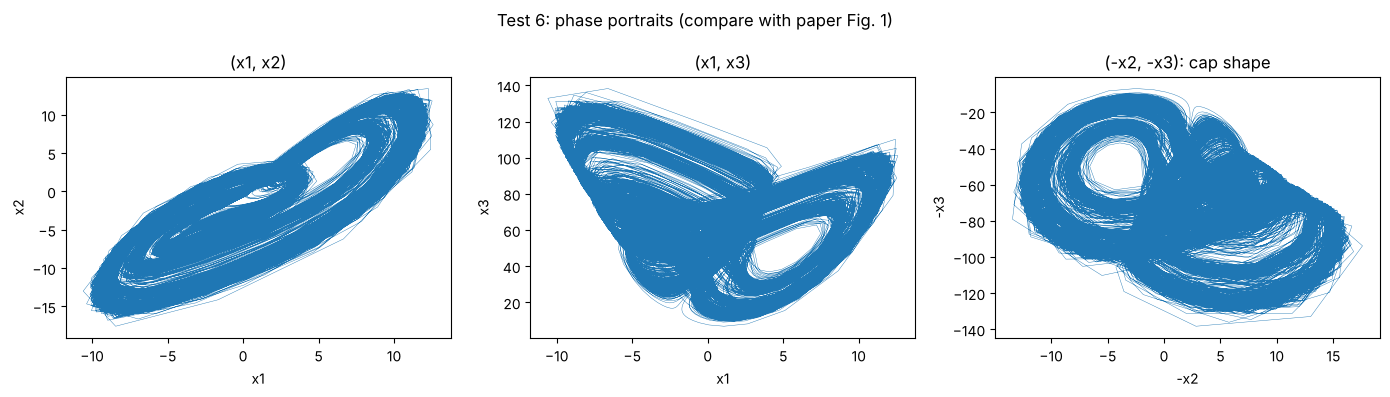

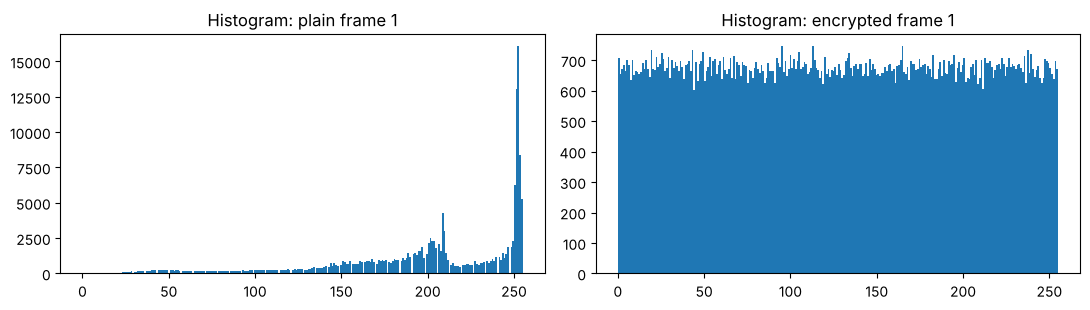


VIDEO ENCRYPTION (FRAMES + AUDIO): 12 TESTS
[ 1] Shannon entropy  ->  PASS
      measured: frames [1, 76, 150]: min encrypted channel entropy = 7.9963 (ideal random sample = 7.9966, max 8); plain min = 4.788; audio: 16-bit 15.8983 (ideal 15.8983, max 16), byte 7.9998
      target  : Near 8 bits (16 for 16-bit audio)
[ 2] Correlation coefficient  ->  PASS
      measured: frame 1 spatial (H/V/D) encrypted max |r| = 0.0058 (plain means 0.991/0.994/0.985); consecutive frames: plain r = 0.9300, encrypted r = 0.0001; audio adjacent samples: encrypted [0.0041, -0.0007], plain [0.999, 0.999]
      target  : Near 0
[ 3] NPCR  ->  FAIL
      measured: frame: 0.00058 %; audio: 0.000208 % (one plain value +1, mean of 3 trials; a pure XOR cipher gives 1/N)
      target  : About 99.6 %
[ 4] UACI  ->  FAIL
      measured: frame: 0.00000 %; audio: 0.000000 %
      target  : About 33.5 %
[ 5] X/Y/Z time series  ->  PASS
      measured: finite = True, max |x| = 138.2; strongest autocorrelation after th

,No,Test,Measured,Target,Status
0,1,Shannon entropy,"frames [1, 76, 150]: min encrypted channel entropy = 7.9963 (ideal random sample = 7.9966, max 8); plain min = 4.788; audio: 16-bit 15.8983 (ideal 15.8983, max 16), byte 7.9998",Near 8 bits (16 for 16-bit audio),PASS
1,2,Correlation coefficient,"frame 1 spatial (H/V/D) encrypted max |r| = 0.0058 (plain means 0.991/0.994/0.985); consecutive frames: plain r = 0.9300, encrypted r = 0.0001; audio adjacent samples: encrypted [0.0041, -0.0007], plain [0.999, 0.999]",Near 0,PASS
2,3,NPCR,"frame: 0.00058 %; audio: 0.000208 % (one plain value +1, mean of 3 trials; a pure XOR cipher gives 1/N)",About 99.6 %,FAIL
3,4,UACI,frame: 0.00000 %; audio: 0.000000 %,About 33.5 %,FAIL
4,5,X/Y/Z time series,"finite = True, max |x| = 138.2; strongest autocorrelation after the first zero crossing: x1 0.60, x2 0.59, x3 0.63 (a periodic signal would give ~1.0)",Bounded and non-repeating (autocorrelation clearly below 0.9),PASS
5,6,Phase portraits,"ranges: x1 [-10.6, 12.6], x2 [-17.6, 13.4], x3 [6.8, 138.2] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1,PASS
6,7,Largest Lyapunov exponent,"LE1 = 0.6028 (own estimate, two-trajectory method, T = 200); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915,PASS
7,8,Initial-condition sensitivity,"each start value changed by 1e-10; keystream bytes changed over 57600 samples: x1(0) 97.4%, x2(0) 97.5%, x3(0) 97.3%, x4(0) 97.4%, x5(0) 97.5%; first different sample index: [1002, 458, 1131, 458, 1017]",Nearly all output changes (>= 95%),PASS
8,9,Histogram chi-square,all encrypted bytes (frames + audio) pooled: p-value = 0.1953 (plain p-value = 0),p-value above 0.05,PASS
9,10,Key sensitivity,"x1(0) +1e-10: frame 1 NPCR 97.41 %, UACI 37.24 %, PSNR 6.78 dB; audio SNR -11.70 dB | parameter a +1e-10: frame 1 NPCR 97.44 %, UACI 37.31 %, PSNR 6.77 dB; audio SNR -11.71 dB | wrong key video: frame 1 NPCR 100.00 %, UACI 65.60 %, PSNR 2.85 dB; audio SNR -4.01 dB","Large, unpredictable change (PSNR < 15 dB, NPCR >= 90 %, audio SNR < 0 dB)",PASS



Note: tests 3 and 4 measure diffusion. A plain XOR cipher has none, so a one-value change in the plain video changes only one cipher value. A low NPCR/UACI here is a property of that design, not a coding error.


In [ ]:
import io, time, json, hashlib, subprocess, csv, warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from scipy.io import wavfile
from google.colab import files

warnings.filterwarnings("ignore")
try:
    from numba import njit
    HAVE_NUMBA = True
except ImportError:
    HAVE_NUMBA = False
    def njit(f):
        return f
    print("WARNING: numba not found. The chaotic solver will be VERY slow (pip install numba).")

# =====================  chaotic model (Eq. 14), RK4 = alpha 1 case  =====================
@njit
def model(s, p):
    x1, x2, x3, x4, x5 = s[0], s[1], s[2], s[3], s[4]
    a, b, c, d, e, g, delta, gamma = p[0], p[1], p[2], p[3], p[4], p[5], p[6], p[7]
    out = np.empty(5)
    out[0] = a * (x2 - x1) + 0.25 * x3 + g * (delta + np.tanh(gamma * x5)) * x3
    out[1] = b * x1 - x1 * x3 + c * x2 - x4
    out[2] = d * x1 * x2 - e * x3
    out[3] = x1
    out[4] = x3
    return out

@njit
def rk4_step(s, p, h):
    k1 = model(s, p)
    k2 = model(s + 0.5 * h * k1, p)
    k3 = model(s + 0.5 * h * k2, p)
    k4 = model(s + h * k3, p)
    return s + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)

@njit
def advance(s, p, h, n_steps):
    for _ in range(n_steps):
        s = rk4_step(s, p, h)
    return s

@njit
def generate_chunk(s, p, h, n_samples, skip):
    out = np.empty((n_samples, 3))
    for i in range(n_samples):
        for _ in range(skip):
            s = rk4_step(s, p, h)
        out[i, 0] = s[0]
        out[i, 1] = s[1]
        out[i, 2] = s[2]
    return out, s

@njit
def benettin(x0, p, h, n_transient, n_renorm, steps_per, d0):
    # largest Lyapunov exponent: two nearby trajectories, renormalised every steps_per steps
    s = advance(x0.copy(), p, h, n_transient)
    v = np.zeros(5)
    v[0] = 1.0
    s2 = s + d0 * v
    acc = 0.0
    for _ in range(n_renorm):
        for _ in range(steps_per):
            s = rk4_step(s, p, h)
            s2 = rk4_step(s2, p, h)
        dd = s2 - s
        nrm = np.sqrt(np.sum(dd * dd))
        acc += np.log(nrm / d0)
        s2 = s + dd * (d0 / nrm)
    return acc / (n_renorm * steps_per * h)

# =====================  secret key and settings  =====================
KEY = dict(
    a=78, b=-16, c=58, d=35, e=15, g=1, delta=1, gamma=0.5,   # paper values
    x0=[0.0, 0.0, 8.0, 6.0, 0.0],                             # initial conditions
)
H_STEP    = 0.001
TRANSIENT = 10000
SKIP      = 10
PARAM_NAMES = ['a', 'b', 'c', 'd', 'e', 'g', 'delta', 'gamma']
IC_NAMES    = ['x1(0)', 'x2(0)', 'x3(0)', 'x4(0)', 'x5(0)']

LE_TIME = 200      # time units used for the Lyapunov exponent (test 7)
IC_EPS  = 1e-10    # size of the tiny start-value change (tests 8 and 10)
KS_L    = 30000    # keystream samples used by the key-space scan (test 11)

def key_to_arrays(key):
    p  = np.array([key[n] for n in PARAM_NAMES], dtype=np.float64)
    x0 = np.array(key['x0'], dtype=np.float64)
    return x0, p

def perturb_key(key, name, eps):
    k = dict(key)
    k['x0'] = list(key['x0'])
    if name in IC_NAMES:
        k['x0'][IC_NAMES.index(name)] += eps
    else:
        k[name] = key[name] + eps
    return k

class ChaoticStream:
    """Chaotic orbit read in consecutive pieces (one piece per frame / signal)."""
    def __init__(self, key):
        x0, self.p = key_to_arrays(key)
        self.s = advance(x0.copy(), self.p, H_STEP, TRANSIENT)    # discard the transient once

    def take(self, n):
        orbit, self.s = generate_chunk(self.s, self.p, H_STEP, n, SKIP)
        if not np.all(np.isfinite(orbit)):
            raise ValueError("The chaotic system blew up. Check your key values.")
        return orbit                                              # (n, 3) = x1, x2, x3

    def byte_keystream(self, n):
        orbit = self.take(n)
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 256).astype(np.uint8)    # (n, 3)

    def frame_keystream(self, H, W):
        return self.byte_keystream(H * W).reshape(H, W, 3)

    def audio_keystream(self, n, channels):
        orbit = self.take(n)[:, :channels]
        return (np.floor(np.abs(orbit) * 1e8).astype(np.int64) % 65536).astype(np.uint16)

_ = ChaoticStream(KEY).take(8)       # warm-up: compiles the numba functions so timings are fair

# =====================  helpers for the 12 tests  =====================
RESULTS = {}
def add(no, name, measured, target, status):
    RESULTS[no] = (name, measured, target, status)

def show_results(title, csv_name):
    rows = [(no,) + RESULTS[no] for no in sorted(RESULTS)]
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)
    for no, name, measured, target, status in rows:
        print(f"[{no:>2}] {name}  ->  {status}")
        print(f"      measured: {measured}")
        print(f"      target  : {target}")
    n_pass = sum(r[4] == 'PASS' for r in rows); n_fail = sum(r[4] == 'FAIL' for r in rows); n_info = sum(r[4] == 'INFO' for r in rows)
    print("-" * 100)
    print(f"PASS: {n_pass}   FAIL: {n_fail}   INFO: {n_info}   (12 tests)")
    with open(csv_name, 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['No', 'Test', 'Measured', 'Target', 'Status']); w.writerows([(r[0], r[1], r[2], r[3], r[4]) for r in rows])
    try:
        files.download(csv_name)
    except Exception:
        pass
    try:
        import pandas as pd
        from IPython.display import display
        pd.set_option('display.max_colwidth', None)
        display(pd.DataFrame(rows, columns=['No', 'Test', 'Measured', 'Target', 'Status']))
    except Exception:
        pass

def entropy_of(values, nbins):
    h = np.bincount(np.asarray(values).ravel(), minlength=nbins) / np.asarray(values).size
    h = h[h > 0]
    return float(-np.sum(h * np.log2(h)))

def entropy_reference(n, nbins, seed=1):
    # entropy of n ideal random values in nbins bins (the best a sample of this size can reach)
    return entropy_of(np.random.default_rng(seed).integers(0, nbins, n), nbins)

def chi2_p(counts):
    return float(stats.chisquare(counts).pvalue)

def corr(x, y):
    return float(np.corrcoef(np.asarray(x, np.float64).ravel(), np.asarray(y, np.float64).ravel())[0, 1])

def corr3(a2d):
    a = a2d.astype(np.float64)
    return [corr(a[:, :-1], a[:, 1:]), corr(a[:-1, :], a[1:, :]), corr(a[:-1, :-1], a[1:, 1:])]   # horizontal, vertical, diagonal

def npcr_uaci(a, b, maxval):
    a = a.astype(np.float64); b = b.astype(np.float64)
    return float((a != b).mean() * 100), float((np.abs(a - b) / maxval).mean() * 100)

def mse(a, b):
    return float(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2))

def psnr(a, b, maxval=255):
    m = mse(a, b)
    return float('inf') if m == 0 else float(10 * np.log10(maxval ** 2 / m))

def snr_db(ref, test):
    noise = np.sum((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float('inf') if noise == 0 else float(10 * np.log10(np.sum(ref.astype(np.float64) ** 2) / noise))

def bump_one(arr, rng, modulus, offset=0):
    """Copy of arr with ONE randomly chosen value increased by one unit (wraps around)."""
    a = arr.copy()
    flat = a.reshape(-1)
    i = int(rng.integers(0, flat.size))
    flat[i] = ((int(flat[i]) + offset + 1) % modulus) - offset
    return a

def model_level_tests(key, ks_len):
    """Tests 5, 6, 7, 8 and 11 (they depend only on the chaotic key, not on the data)."""
    x0, p = key_to_arrays(key)

    # ---- tests 5 + 6: time series and phase portraits (orbit of 20000 samples = 200 time units)
    n = 20000
    orbit = ChaoticStream(key).take(n)
    t = np.arange(n) * H_STEP * SKIP
    finite = bool(np.isfinite(orbit).all()); bound = float(np.abs(orbit).max())
    acs = []
    for k in range(3):
        x = orbit[:, k] - orbit[:, k].mean()
        f = np.fft.rfft(x, 2 * n); ac = np.fft.irfft(f * np.conj(f))[:n]; ac /= ac[0]
        z = int(np.argmax(ac < 0)); acs.append(float(ac[z:n // 2].max()))
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for k, nm in enumerate(['x1', 'x2', 'x3']):
        ax[k].plot(t[:3000], orbit[:3000, k], lw=0.6); ax[k].set_ylabel(nm)
    ax[2].set_xlabel('time (first 30 time units shown)'); ax[0].set_title('Test 5: x1, x2, x3 time series')
    plt.tight_layout(); plt.show()
    add(5, 'X/Y/Z time series',
        f"finite = {finite}, max |x| = {bound:.1f}; strongest autocorrelation after the first zero crossing: "
        f"x1 {acs[0]:.2f}, x2 {acs[1]:.2f}, x3 {acs[2]:.2f} (a periodic signal would give ~1.0)",
        'Bounded and non-repeating (autocorrelation clearly below 0.9)',
        'PASS' if (finite and bound < 1e4 and max(acs) < 0.9) else 'FAIL')

    rng_ = [(float(orbit[:, k].min()), float(orbit[:, k].max())) for k in range(3)]
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    ax[0].plot(orbit[:, 0], orbit[:, 1], lw=0.3); ax[0].set_xlabel('x1'); ax[0].set_ylabel('x2'); ax[0].set_title('(x1, x2)')
    ax[1].plot(orbit[:, 0], orbit[:, 2], lw=0.3); ax[1].set_xlabel('x1'); ax[1].set_ylabel('x3'); ax[1].set_title('(x1, x3)')
    ax[2].plot(-orbit[:, 1], -orbit[:, 2], lw=0.3); ax[2].set_xlabel('-x2'); ax[2].set_ylabel('-x3'); ax[2].set_title('(-x2, -x3): cap shape')
    plt.suptitle('Test 6: phase portraits (compare with paper Fig. 1)'); plt.tight_layout(); plt.show()
    in_box = (-20 <= rng_[0][0] and rng_[0][1] <= 20 and -25 <= rng_[1][0] and rng_[1][1] <= 25 and -5 <= rng_[2][0] and rng_[2][1] <= 160)
    add(6, 'Phase portraits',
        f"ranges: x1 [{rng_[0][0]:.1f}, {rng_[0][1]:.1f}], x2 [{rng_[1][0]:.1f}, {rng_[1][1]:.1f}], x3 [{rng_[2][0]:.1f}, {rng_[2][1]:.1f}] (paper Fig. 1: x1 about -12..13, x2 about -16..14, x3 about 0..130)",
        'Cap-like attractor of this 5D model (the butterfly shape belongs to the Lorenz system); same extent as paper Fig. 1',
        'PASS' if (finite and in_box) else 'FAIL')

    # ---- test 7: largest Lyapunov exponent
    n_renorm = int(LE_TIME / (H_STEP * 100))
    le = float(benettin(x0, p, H_STEP, TRANSIENT, n_renorm, 100, 1e-9))
    add(7, 'Largest Lyapunov exponent',
        f"LE1 = {le:.4f} (own estimate, two-trajectory method, T = {LE_TIME}); the paper's Table 1 lists LE1 = 0.99150 for alpha = 1",
        'Positive (chaos). Standard Lorenz: about 0.906; this paper: 0.9915',
        'PASS' if le > 0.01 else 'FAIL')

    # ---- test 8: initial-condition sensitivity (tiny change in each start value)
    ref = ChaoticStream(key).byte_keystream(ks_len)
    fr, first = [], []
    for i, nm in enumerate(IC_NAMES):
        b = ChaoticStream(perturb_key(key, nm, IC_EPS)).byte_keystream(ks_len)
        ch = (b != ref)
        fr.append(float(ch.mean() * 100)); first.append(int(np.argmax(ch.any(axis=1))) if ch.any() else -1)
    add(8, 'Initial-condition sensitivity',
        f"each start value changed by {IC_EPS:g}; keystream bytes changed over {ks_len} samples: "
        + ', '.join(f"{nm} {v:.1f}%" for nm, v in zip(IC_NAMES, fr)) + f"; first different sample index: {first}",
        'Nearly all output changes (>= 95%)',
        'PASS' if min(fr) >= 95 else 'FAIL')

    # ---- test 11: effective key space (13 key values: 8 parameters + 5 initial conditions)
    refL = ChaoticStream(key).byte_keystream(KS_L)
    grid = [10.0 ** (-k) for k in range(16, 3, -1)]            # 1e-16 ... 1e-4
    def diverged(k2):
        return float((ChaoticStream(k2).byte_keystream(KS_L) != refL).mean()) >= 0.5
    parts, bits = [], 0.0
    for nm in IC_NAMES + PARAM_NAMES:
        val = key['x0'][IC_NAMES.index(nm)] if nm in IC_NAMES else key[nm]
        delta_i = None
        for j, eps in enumerate(grid):
            if diverged(perturb_key(key, nm, eps)) and (j + 1 >= len(grid) or diverged(perturb_key(key, nm, grid[j + 1]))):
                delta_i = eps; break
        if delta_i is None:
            parts.append(f"{nm}: no effect"); continue
        b_i = float(np.log2(max(abs(val), 1.0) / delta_i)); bits += b_i
        parts.append(f"{nm}: step {delta_i:.0e} ({b_i:.1f} bits)")
    add(11, 'Effective key space',
        f"about 2^{bits:.0f} distinguishable keys (13 key values; resolution where the keystream changes completely): " + '; '.join(parts) +
        ". Upper bound: assumes every key value can vary independently, and not every value stays chaotic",
        'Large and well defined (common requirement: at least 2^100)',
        'PASS' if bits >= 100 else 'FAIL')

# =====================  VIDEO: settings  =====================
USE_KEY_VIDEO = True       # ONE key video: its first frame = key image, its audio track = key audio
MAX_SECONDS   = 5          # only the first N seconds are processed (None = whole video)
SCALE_WIDTH   = 320        # frames are resized to this width (None = keep size, only made even)
DOWNLOAD_OUTPUTS = False   # True = also download encrypted_video.mkv / decrypted_video.mp4

# =====================  ffmpeg helpers  =====================
from fractions import Fraction

def run(cmd, **kw):
    r = subprocess.run(cmd, capture_output=True, **kw)
    if r.returncode != 0:
        raise RuntimeError(r.stderr.decode(errors='ignore')[-800:])
    return r

def first_frame_size(path):
    r = run(['ffmpeg', '-v', 'error', '-i', path, '-frames:v', '1', '-f', 'image2pipe', '-vcodec', 'png', '-'])
    return Image.open(io.BytesIO(r.stdout)).size            # (W, H)

def video_fps(path):
    r = run(['ffprobe', '-v', 'error', '-select_streams', 'v:0', '-show_entries', 'stream=r_frame_rate', '-of', 'json', path])
    return json.loads(r.stdout)['streams'][0]['r_frame_rate']

def target_size(W, H, scale_width):
    if scale_width:
        nw = scale_width // 2 * 2
        nh = int(round(H * nw / W)) // 2 * 2
    else:
        nw, nh = W // 2 * 2, H // 2 * 2
    return nw, nh

def read_frames(path, nw, nh, scale, max_seconds=None):
    cmd = ['ffmpeg', '-v', 'error']
    if max_seconds: cmd += ['-t', str(max_seconds)]
    vf = f'scale={nw}:{nh}:flags=lanczos' if scale else f'crop={nw}:{nh}'
    cmd += ['-i', path, '-an', '-vf', vf, '-f', 'rawvideo', '-pix_fmt', 'rgb24', '-']
    raw = run(cmd).stdout
    size = nw * nh * 3
    return [np.frombuffer(raw[i:i + size], np.uint8).reshape(nh, nw, 3).copy() for i in range(0, len(raw) - size + 1, size)]

def read_audio(path, max_seconds=None):
    cmd = ['ffmpeg', '-y', '-v', 'error']
    if max_seconds: cmd += ['-t', str(max_seconds)]
    try:
        run(cmd + ['-i', path, '-vn', '-acodec', 'pcm_s16le', 'tmp_audio.wav'])
    except RuntimeError:
        return None, None
    sr_, data = wavfile.read('tmp_audio.wav')
    return sr_, (np.ascontiguousarray(data) if data.size else None)

def write_lossless_mkv(path, frames, fps, sr_=None, audio=None):
    H_, W_, _ = frames[0].shape
    cmd = ['ffmpeg', '-y', '-v', 'error', '-f', 'rawvideo', '-pix_fmt', 'rgb24', '-s', f'{W_}x{H_}', '-framerate', fps, '-i', '-']
    if audio is not None:
        wavfile.write('tmp_enc_audio.wav', sr_, audio)
        cmd += ['-i', 'tmp_enc_audio.wav']
    cmd += ['-c:v', 'ffv1', '-pix_fmt', 'bgr0']
    if audio is not None: cmd += ['-c:a', 'pcm_s16le']      # no -shortest: keep EVERY audio sample (audio may be slightly longer than the video)
    cmd += [path]
    subprocess.run(cmd, input=b''.join(f.tobytes() for f in frames), check=True, capture_output=True)

def write_viewable_mp4(path, frames, fps, sr_=None, audio=None):
    H_, W_, _ = frames[0].shape
    cmd = ['ffmpeg', '-y', '-v', 'error', '-f', 'rawvideo', '-pix_fmt', 'rgb24', '-s', f'{W_}x{H_}', '-framerate', fps, '-i', '-']
    if audio is not None:
        wavfile.write('tmp_view_audio.wav', sr_, audio)
        cmd += ['-i', 'tmp_view_audio.wav', '-c:a', 'aac', '-shortest']
    cmd += ['-c:v', 'libx264', '-crf', '17', '-pix_fmt', 'yuv420p', path]
    subprocess.run(cmd, input=b''.join(f.tobytes() for f in frames), check=True, capture_output=True)

def load_key_image(data, name, nw, nh):
    if len(data) < 1000:
        raise ValueError(f"{name} is only {len(data)} bytes: empty or a placeholder. Upload the real file.")
    try:
        im = Image.open(io.BytesIO(data)).convert('RGB')
    except Exception:
        with open(name, 'wb') as f:
            f.write(data)
        try:
            r = run(['ffmpeg', '-v', 'error', '-i', name, '-frames:v', '1', '-f', 'image2pipe', '-vcodec', 'png', '-'])
            im = Image.open(io.BytesIO(r.stdout)).convert('RGB')
        except Exception:
            raise ValueError(f"{name} is neither a readable image nor a video.") from None
    return np.array(im.resize((nw, nh)), dtype=np.uint8)

def load_key_audio(data, name):
    with open(name, 'wb') as f:
        f.write(data)
    try:
        run(['ffmpeg', '-y', '-v', 'error', '-i', name, '-vn', '-acodec', 'pcm_s16le', 'tmp_key_audio.wav'])
        _, k = wavfile.read('tmp_key_audio.wav')
    except Exception:
        return None
    return np.ascontiguousarray(k) if k.size else None

# =====================  encrypt / decrypt functions  =====================
def xor_frames(frames, key, key_img=None):
    stream = ChaoticStream(key)
    out = []
    for f in frames:
        c = f ^ stream.frame_keystream(f.shape[0], f.shape[1])      # every frame gets the NEXT part of the orbit
        if key_img is not None:
            c = c ^ key_img
        out.append(c)
    return out

def as_2d(x):
    return x.reshape(-1, 1) if x.ndim == 1 else x

def prepare_key_audio(key_audio, n, ch):
    k = as_2d(key_audio)
    k = np.tile(k, (int(np.ceil(n / k.shape[0])), 1))[:n]
    k = k[:, :ch] if k.shape[1] >= ch else np.tile(k[:, :1], (1, ch))
    return np.ascontiguousarray(k).view(np.uint16)

def xor_audio(audio, key, key_audio=None):
    a2 = np.ascontiguousarray(as_2d(audio))
    n, ch = a2.shape
    c = a2.view(np.uint16) ^ ChaoticStream(key).audio_keystream(n, ch)
    if key_audio is not None:
        c = c ^ prepare_key_audio(key_audio, n, ch)
    return c.view(np.int16).reshape(audio.shape)

# =====================  upload plain video and key video  =====================
print("Upload the PLAIN video:")
up = files.upload(); video_name = list(up.keys())[0]
if len(up[video_name]) < 10_000:
    raise ValueError(f"{video_name} is only {len(up[video_name])} bytes: empty or a placeholder. Upload the real video.")
with open(video_name, 'wb') as f:
    f.write(up[video_name])
try:
    W0, H0 = first_frame_size(video_name)
except RuntimeError as err:
    raise ValueError(f"ffmpeg cannot read {video_name} (corrupted or incomplete?).\n" + str(err)) from None
NW, NH = target_size(W0, H0, SCALE_WIDTH)
FPS = video_fps(video_name)
plain_frames = read_frames(video_name, NW, NH, scale=bool(SCALE_WIDTH), max_seconds=MAX_SECONDS)
sr, plain_audio = read_audio(video_name, MAX_SECONDS)

key_img, key_audio = None, None
if USE_KEY_VIDEO:
    print("Upload the KEY video (different from the plain video):")
    up = files.upload(); kname = list(up.keys())[0]
    key_img = load_key_image(up[kname], kname, NW, NH)
    if plain_audio is not None:
        key_audio = load_key_audio(up[kname], kname)
print(f"Plain video {video_name}: {W0}x{H0} -> working size {NW}x{NH}, {len(plain_frames)} frames at {FPS} fps; "
      + ("no audio" if plain_audio is None else f"audio {sr} Hz {plain_audio.shape}")
      + f"; key: image {'yes' if key_img is not None else 'no'}, audio {'yes' if key_audio is not None else 'no'}")

# =====================  encrypt, save lossless, read back, decrypt (timed)  =====================
t0 = time.perf_counter(); enc_frames = xor_frames(plain_frames, KEY, key_img); t_enc_f = time.perf_counter() - t0
t0 = time.perf_counter(); enc_audio = xor_audio(plain_audio, KEY, key_audio) if plain_audio is not None else None; t_enc_a = time.perf_counter() - t0
write_lossless_mkv("encrypted_video.mkv", enc_frames, FPS, sr, enc_audio)
cipher_frames = read_frames("encrypted_video.mkv", NW, NH, scale=False)
cipher_sr, cipher_audio = read_audio("encrypted_video.mkv")

t0 = time.perf_counter(); dec_frames = xor_frames(cipher_frames, KEY, key_img); t_dec_f = time.perf_counter() - t0
t0 = time.perf_counter(); dec_audio = xor_audio(cipher_audio, KEY, key_audio) if cipher_audio is not None else None; t_dec_a = time.perf_counter() - t0

frames_ok = len(dec_frames) == len(plain_frames) and all(np.array_equal(a, b) for a, b in zip(dec_frames, plain_frames))
audio_ok = (dec_audio is None and plain_audio is None) or (dec_audio is not None and plain_audio is not None
            and dec_audio.shape == plain_audio.shape and np.array_equal(dec_audio, plain_audio))
print("All frames identical to the original:", frames_ok, f"({len(dec_frames)} frames)")
print("Audio identical to the original     :", audio_ok)
if DOWNLOAD_OUTPUTS:
    write_viewable_mp4("decrypted_video.mp4", dec_frames, FPS, cipher_sr, dec_audio)
    files.download("encrypted_video.mkv"); files.download("decrypted_video.mp4")

nF = len(plain_frames); f0 = plain_frames[0]; e0 = enc_frames[0]
bad_f0 = xor_frames([cipher_frames[0]], perturb_key(KEY, 'x1(0)', IC_EPS), key_img)[0]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.5))
for a, im, ttl in zip(ax, [f0, e0, dec_frames[0], bad_f0], ['Plain frame 1', 'Encrypted frame 1', 'Decrypted frame 1', f'x1(0) off by {IC_EPS:g}']):
    a.imshow(im); a.set_title(ttl); a.axis('off')
plt.show()

# =====================  the 12 tests  =====================
rng = np.random.default_rng(7)
has_audio = plain_audio is not None and enc_audio is not None
if has_audio:
    P2, C2 = as_2d(plain_audio), as_2d(enc_audio)
    bytes_pa = np.ascontiguousarray(P2).view(np.uint8); bytes_ca = np.ascontiguousarray(C2).view(np.uint8)

# 1) Shannon entropy
idx = sorted(set([0, nF // 2, nF - 1]))
ref8 = entropy_reference(NH * NW, 256)
ent_c = [[entropy_of(enc_frames[i][..., k], 256) for k in range(3)] for i in idx]
ent_p = [[entropy_of(plain_frames[i][..., k], 256) for k in range(3)] for i in idx]
ok1 = min(min(r) for r in ent_c) >= ref8 - 0.02
txt1 = f"frames {[i + 1 for i in idx]}: min encrypted channel entropy = {min(min(r) for r in ent_c):.4f} (ideal random sample = {ref8:.4f}, max 8); plain min = {min(min(r) for r in ent_p):.3f}"
if has_audio:
    ref16 = entropy_reference(P2.size, 65536); e16 = entropy_of(C2.view(np.uint16), 65536)
    ref8a = entropy_reference(bytes_ca.size, 256); e8a = entropy_of(bytes_ca, 256)
    ok1 &= (e16 >= ref16 - 0.02 and e8a >= ref8a - 0.01)
    txt1 += f"; audio: 16-bit {e16:.4f} (ideal {ref16:.4f}, max 16), byte {e8a:.4f}"
add(1, 'Shannon entropy', txt1, 'Near 8 bits (16 for 16-bit audio)', 'PASS' if ok1 else 'FAIL')

# 2) Correlation coefficient: spatial (frame 1), temporal (consecutive frames), audio
cp = np.array([corr3(f0[..., k]) for k in range(3)]); cc = np.array([corr3(e0[..., k]) for k in range(3)])
m_t = min(20, nF - 1)
tp = float(np.mean([corr(plain_frames[i], plain_frames[i + 1]) for i in range(m_t)])) if m_t > 0 else float('nan')
te = float(np.mean([corr(enc_frames[i], enc_frames[i + 1]) for i in range(m_t)])) if m_t > 0 else float('nan')
worst = max(float(np.abs(cc).max()), abs(te) if m_t > 0 else 0.0)
txt2 = (f"frame 1 spatial (H/V/D) encrypted max |r| = {np.abs(cc).max():.4f} (plain means {cp[:, 0].mean():.3f}/{cp[:, 1].mean():.3f}/{cp[:, 2].mean():.3f}); "
        f"consecutive frames: plain r = {tp:.4f}, encrypted r = {te:.4f}")
if has_audio:
    ca_ = [corr(C2[:-1, k], C2[1:, k]) for k in range(C2.shape[1])]; pa_ = [corr(P2[:-1, k], P2[1:, k]) for k in range(P2.shape[1])]
    worst = max(worst, max(abs(v) for v in ca_)); txt2 += f"; audio adjacent samples: encrypted {[round(v, 4) for v in ca_]}, plain {[round(v, 3) for v in pa_]}"
add(2, 'Correlation coefficient', txt2, 'Near 0', 'PASS' if worst < 0.05 else 'FAIL')

# 3) + 4) NPCR and UACI after changing ONE plain value by one unit (3 random trials)
nf, uf, na, ua = [], [], [], []
for _ in range(3):
    c2 = xor_frames([bump_one(f0, rng, 256)], KEY, key_img)[0]
    n_, u_ = npcr_uaci(e0, c2, 255); nf.append(n_); uf.append(u_)
    if has_audio:
        c2a = xor_audio(bump_one(plain_audio, rng, 65536, offset=32768), KEY, key_audio)
        n_, u_ = npcr_uaci(enc_audio, c2a, 65535); na.append(n_); ua.append(u_)
n_all = [float(np.mean(nf))] + ([float(np.mean(na))] if has_audio else [])
u_all = [float(np.mean(uf))] + ([float(np.mean(ua))] if has_audio else [])
t3 = f"frame: {n_all[0]:.5f} %" + (f"; audio: {n_all[1]:.6f} %" if has_audio else "") + " (one plain value +1, mean of 3 trials; a pure XOR cipher gives 1/N)"
t4 = f"frame: {u_all[0]:.5f} %" + (f"; audio: {u_all[1]:.6f} %" if has_audio else "")
add(3, 'NPCR', t3, 'About 99.6 %', 'PASS' if min(n_all) >= 99.0 else 'FAIL')
add(4, 'UACI', t4, 'About 33.5 %', 'PASS' if all(32.0 <= u <= 35.0 for u in u_all) else 'FAIL')

# 5), 6), 7), 8), 11) chaotic-key tests (test 8 uses the keystream length of one frame)
model_level_tests(KEY, NH * NW)

# 9) Histogram chi-square (all encrypted frame bytes + audio bytes pooled into one test)
counts_c = sum(np.bincount(f.ravel(), minlength=256) for f in enc_frames)
counts_p = sum(np.bincount(f.ravel(), minlength=256) for f in plain_frames)
if has_audio:
    counts_c = counts_c + np.bincount(bytes_ca.ravel(), minlength=256); counts_p = counts_p + np.bincount(bytes_pa.ravel(), minlength=256)
p_c, p_p = chi2_p(counts_c), chi2_p(counts_p)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(f0.ravel(), bins=256, range=(0, 255)); ax[0].set_title('Histogram: plain frame 1')
ax[1].hist(e0.ravel(), bins=256, range=(0, 255)); ax[1].set_title('Histogram: encrypted frame 1')
plt.tight_layout(); plt.show()
add(9, 'Histogram chi-square', f"all encrypted bytes (frames{' + audio' if has_audio else ''}) pooled: p-value = {p_c:.4f} (plain p-value = {p_p:.2g})", 'p-value above 0.05', 'PASS' if p_c > 0.05 else 'FAIL')

# 10) Key sensitivity: decrypt with a slightly wrong key
variants = [(f'x1(0) +{IC_EPS:g}', perturb_key(KEY, 'x1(0)', IC_EPS), key_img, key_audio),
            (f'parameter a +{IC_EPS:g}', perturb_key(KEY, 'a', IC_EPS), key_img, key_audio)]
if key_img is not None:
    variants.append(('wrong key video', KEY, 255 - key_img, None if key_audio is None else np.ascontiguousarray(key_audio[::-1])))
lines, ok10 = [], True
for nm, k2, ki2, ka2 in variants:
    d2 = xor_frames([cipher_frames[0]], k2, ki2)[0]
    n_, u_ = npcr_uaci(d2, f0, 255); ps = psnr(d2, f0)
    ln = f"{nm}: frame 1 NPCR {n_:.2f} %, UACI {u_:.2f} %, PSNR {ps:.2f} dB"
    ok10 &= (n_ >= 90 and ps < 15)
    if has_audio:
        da = xor_audio(cipher_audio, k2, ka2); sn = snr_db(plain_audio, da)
        ln += f"; audio SNR {sn:.2f} dB"; ok10 &= (sn < 0)
    lines.append(ln)
add(10, 'Key sensitivity', ' | '.join(lines), 'Large, unpredictable change (PSNR < 15 dB, NPCR >= 90 %, audio SNR < 0 dB)', 'PASS' if ok10 else 'FAIL')

# 12) Performance and throughput
mbf = sum(f.size for f in plain_frames) / 1e6
txt12 = (f"frames: {nF} frames of {NW}x{NH} ({mbf:.1f} MB): encrypt {t_enc_f:.2f} s ({nF / t_enc_f:.1f} fps, {mbf / t_enc_f:.2f} MB/s), "
         f"decrypt {t_dec_f:.2f} s ({nF / t_dec_f:.1f} fps)")
if has_audio:
    dur = plain_audio.shape[0] / sr; mba = plain_audio.nbytes / 1e6
    txt12 += f"; audio: {dur:.2f} s ({mba:.2f} MB): encrypt {t_enc_a:.2f} s ({dur / t_enc_a:.1f}x real time), decrypt {t_dec_a:.2f} s"
fps_val = float(Fraction(FPS))
txt12 += f"; video plays at {fps_val:.1f} fps, so real-time factor for frames = {(nF / fps_val) / t_enc_f:.2f}x; numba = {HAVE_NUMBA}"
add(12, 'Performance and throughput', txt12, 'High (software only here)', 'INFO')

show_results("VIDEO ENCRYPTION (FRAMES + AUDIO): 12 TESTS", "video_12_tests.csv")
print("\nNote: tests 3 and 4 measure diffusion. A plain XOR cipher has none, so a one-value change in the plain video changes only one cipher value. A low NPCR/UACI here is a property of that design, not a coding error.")